# Práctica 2 · Trading con aprendizaje por refuerzo: algoritmo A3C

Esta libreta resuelve la parte de **A3C** de la práctica 2 (la parte de DQN está en `practica-2-RL-Algoritmo-DQN.ipynb`). Es la continuación de la práctica 1, así que se reutilizan **sin modificaciones** el entorno `SimpleTradingEnv`, las cuatro funciones generadoras de precios y **el mismo protocolo de evaluación** (mismas series de validación y de test, mismas métricas, mismas referencias y mismo criterio de convergencia). El código compartido está en `../trader_rl.py`. Así, los resultados de A3C se pueden comparar directamente con los de Q-Learning, SARSA y Monte Carlo (`../tabla_comparativa.csv`) y con los de DQN (`resultados_dqn.csv`).

**Qué pide el enunciado y dónde se responde**

| Ejercicio | Dónde |
|---|---|
| 1. Implementar A3C y probarlo con las cuatro funciones de precios, una serie nueva en cada episodio, y evaluar en series de test nuevas | secciones 3–5 y 7 |
| 2. Analizar las soluciones y compararlas con el agente aleatorio y con *buy & hold*; ¿es la estrategia la esperada? | secciones 7 y 8 |
| 3. Ajustar hiperparámetros: tasa de aprendizaje, exploración (aquí, la entropía), $\gamma$ y nº de episodios | sección 6 |
| 4. Tabla comparativa con *baselines*: rendimiento y tiempo de convergencia | sección 7 |

**Más allá de los mínimos:** efecto del **número de trabajadores asíncronos** (con uno solo, A3C es un actor-crítico de $n$ pasos síncrono), de la **entropía** (que en A3C hace el papel de $\epsilon$), política **greedy frente a estocástica**, **estado ampliado** que la red usa sin discretizar, y comparación con los algoritmos tabulares de la práctica 1 y con DQN.

**Contenido**

1. Configuración y recordatorio del entorno
2. Preparar el estado y la recompensa para la red
3. El algoritmo A3C
4. Primer entrenamiento (comprobación)
5. Protocolo de evaluación y *baselines*
6. Ajuste de hiperparámetros
7. Entrenamiento final, curvas de aprendizaje y resultados en test
8. Análisis: política aprendida, trabajadores, entropía, política estocástica y estado ampliado
9. Conclusiones y limitaciones

**Requisitos:** Python ≥ 3.10 con `torch`, `gymnasium`, `numpy`, `pandas`, `matplotlib` y `joblib`, y el fichero `a3c_lib.py` de esta carpeta. Los resultados costosos se guardan en `cache_a3c/` y las figuras en `figuras_a3c/`; con `RECOMPUTE = False` (valor por defecto) se cargan sin volver a entrenar. **Entrenarlo todo desde cero tarda más de una hora** (12 núcleos).

## 1. Configuración y recordatorio del entorno

In [1]:
import os
import sys
import json
import time
import random
import inspect
import warnings
import threading
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from joblib import Parallel, delayed, dump, load
from IPython.display import display

warnings.filterwarnings("ignore")
torch.set_num_threads(1)

# trader_rl.py (práctica 1) está en la carpeta superior y a3c_lib.py en esta: se añaden a la ruta también para los procesos hijos
AQUI, PADRE = str(Path.cwd()), str(Path.cwd().parent)
for ruta in (AQUI, PADRE):
    sys.path.insert(0, ruta)
os.environ["PYTHONPATH"] = os.pathsep.join([AQUI, PADRE, os.environ.get("PYTHONPATH", "")])

import a3c_lib as A
from trader_rl import (GENERATORS, SimpleTradingEnv, ExtendedTradingEnv, make_series, val_sets, test_sets, N_STEPS, N_VAL, N_TEST,
                       SEED_TRAIN, SEED_CALIB, SEED_VAL, SEED_TEST, evaluate, run_episode, BASELINES, summarize, convergence_episode)

GENS = list(GENERATORS)
CACHE, FIGS = Path("cache_a3c"), Path("figuras_a3c")
CACHE.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False      # True: vuelve a entrenarlo todo (más de una hora con 12 núcleos); False: carga cache_a3c/
MODO_RAPIDO = False    # True: presupuesto minúsculo, solo para comprobar que la libreta corre de punta a punta
N_CORES = max(1, min(12, os.cpu_count() or 1))

# Presupuesto de entrenamiento
WORKERS = 4                                                        # trabajadores asíncronos por entrenamiento
N_CONFIGS, N_EP_BUSQUEDA, EVAL_BUSQUEDA, SEMILLAS_BUSQUEDA = 16, 500, 50, (100, 101)   # búsqueda aleatoria (corta)
TOP_K, SEMILLAS_REEVAL = 2, (200, 201)                             # reevaluación con entrenamiento completo
N_EP_FINAL, EVAL_CADA, SEMILLAS_FINAL = 1500, 50, (0, 1, 2, 3, 4)  # entrenamiento final (5 semillas)
N_EP_EXTRA, SEMILLAS_EXTRA = 1000, (300, 301)                      # experimentos adicionales
N_EP_COSTE, REP_COSTE = 100, 2                                     # medida del coste por episodio
if MODO_RAPIDO:
    N_CONFIGS, N_EP_BUSQUEDA, EVAL_BUSQUEDA, SEMILLAS_BUSQUEDA = 4, 100, 25, (100,)
    TOP_K, SEMILLAS_REEVAL, N_EP_FINAL, EVAL_CADA, SEMILLAS_FINAL = 1, (200,), 100, 25, (0, 1)
    N_EP_EXTRA, SEMILLAS_EXTRA, N_EP_COSTE, REP_COSTE = 100, (300,), 20, 1
    RECOMPUTE, CACHE, FIGS = True, Path("cache_a3c_rapido"), Path("figuras_a3c_rapido")
    CACHE.mkdir(exist_ok=True)
    FIGS.mkdir(exist_ok=True)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
print(f"torch {torch.__version__} | {N_CORES} núcleos | RECOMPUTE={RECOMPUTE}")

torch 2.14.0+cpu | 12 núcleos | RECOMPUTE=False


**El entorno** es exactamente el del enunciado (el de la práctica 1):

- **Estado:** `(tendencia, posición)`. La tendencia es $(p_t - \bar p_{t-5:t})/\bar p_{t-5:t}$ (precio actual frente a la media de los últimos 6 precios), recortada a $[-1,1]$; la posición es 1 si se tiene el activo y 0 si no.
- **Acciones:** 0 = vender, 1 = mantener, 2 = comprar. Vender solo tiene efecto si se tiene el activo, y comprar solo si no se tiene.
- **Recompensa:** el cambio relativo del precio mientras se mantiene la posición, menos un 0,1 % de comisión en cada compra o venta. Se actúa al precio anterior, así que no hay información del futuro.
- **Episodio:** una serie de 500 precios (494 pasos de decisión). Capital inicial de 1000.

**Protocolo de datos** (el de la práctica 1; los rangos de semillas son disjuntos, así que ninguna serie se reutiliza entre conjuntos):

,conjunto,series,semillas de las series,para qué
0,entrenamiento,1 nueva por episodio (1500 episodios por entre...,0 + 10 000·semilla + episodio,aprender
1,calibración (escalas),40,100000 + i,normalizar la entrada de la red
2,validación,30 (siempre las mismas),500000 + i,elegir hiperparámetros y dibujar curvas
3,test,100 (siempre las mismas),900000 + i,evaluación final (no se usa para ajustar nada)


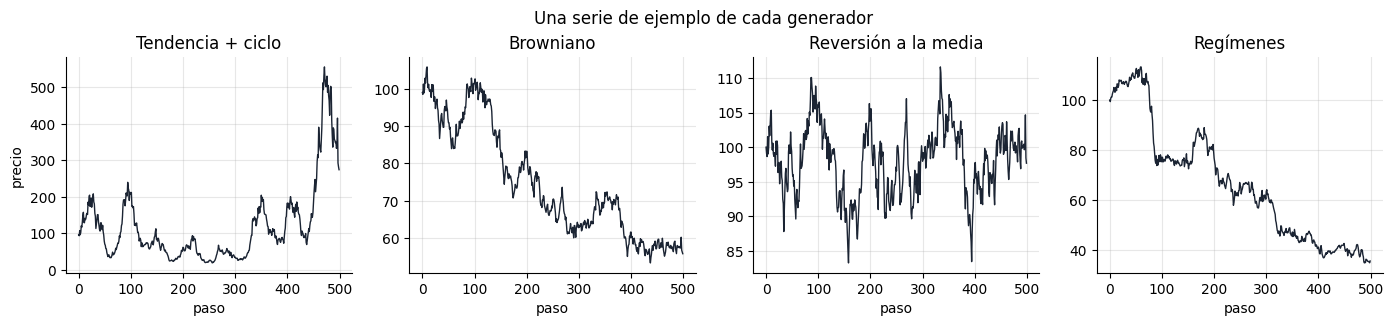

In [2]:
protocolo = pd.DataFrame({
    "conjunto": ["entrenamiento", "calibración (escalas)", "validación", "test"],
    "series": [f"1 nueva por episodio ({N_EP_FINAL} episodios por entrenamiento)", "40", f"{N_VAL} (siempre las mismas)", f"{N_TEST} (siempre las mismas)"],
    "semillas de las series": [f"{SEED_TRAIN} + 10 000·semilla + episodio", f"{SEED_CALIB} + i", f"{SEED_VAL} + i", f"{SEED_TEST} + i"],
    "para qué": ["aprender", "normalizar la entrada de la red", "elegir hiperparámetros y dibujar curvas", "evaluación final (no se usa para ajustar nada)"]})
display(protocolo)

fig, axs = plt.subplots(1, 4, figsize=(17, 2.8))
for ax, g in zip(axs, GENS):
    ax.plot(make_series(g, SEED_VAL), color="#1b2433", lw=1)
    ax.set_title(g)
    ax.set_xlabel("paso")
axs[0].set_ylabel("precio")
fig.suptitle("Una serie de ejemplo de cada generador", y=1.05)
plt.show()

## 2. Preparar el estado y la recompensa para la red

Igual que en DQN: A3C usa una red neuronal, que admite entradas continuas, así que **no hace falta discretizar**, pero sí **normalizar**. La tendencia vive en rangos muy distintos según el mercado (en torno a ±0,3 en *tendencia + ciclo* y ±0,03 en los demás), y una red entrenada con descenso de gradiente aprende mal con entradas de escalas tan dispares.

- **Entrada de la red:** `[(tendencia − media) / desviación, posición]`, con la media y la desviación calculadas **por mercado** en 40 series de calibración (semillas disjuntas de las de entrenamiento, validación y test). Se recorta a $\pm 5$ desviaciones.
- **Recompensa:** se divide por la desviación típica del retorno por paso de cada mercado. Es una constante positiva, así que **no cambia qué política es óptima**, pero deja las ventajas y el valor que estima el crítico en una escala ~1 en todos los mercados. Esto importa más en A3C que en DQN: la pérdida del actor es proporcional a la ventaja, y el crítico y el actor comparten el cuerpo de la red, así que una escala de la recompensa muy distinta entre mercados descompensaría las dos pérdidas.
- **Acciones válidas:** sin activo solo se consideran {mantener, comprar} y con activo {vender, mantener}, porque las otras no tienen efecto. En A3C se enmascaran los logits de las acciones sin efecto, de modo que $\pi$ es una distribución sobre las dos acciones que cuentan y la entropía se calcula solo sobre ellas.

In [3]:
t0 = time.perf_counter()
ESCALAS = {g: A.calibrar(g) for g in GENS}
ESCALAS_EXT = {g: A.calibrar(g, "ExtendedTradingEnv") for g in GENS}
print(f"calibración en {time.perf_counter() - t0:.0f} s")
display(pd.DataFrame({g: {"media de la tendencia": ESCALAS[g][0][0], "desviación de la tendencia": ESCALAS[g][1][0],
                          "desviación de la recompensa por paso": ESCALAS[g][2]} for g in GENS}).T.round(4))

calibración en 4 s


,media de la tendencia,desviación de la tendencia,desviación de la recompensa por paso
Tendencia + ciclo,0.0222,0.1533,0.1063
Browniano,-0.0001,0.0250,0.0201
Reversión a la media,0.0001,0.0245,0.0205
Regímenes,-0.0005,0.0231,0.0186


## 3. El algoritmo A3C

**A3C** (*Asynchronous Advantage Actor-Critic*) es un método **actor-crítico**: en lugar de aprender los valores $Q(s,a)$ y derivar de ellos una política (como DQN), aprende **directamente la política** $\pi_\theta(a|s)$ (el *actor*) a la vez que una estimación del valor del estado $V_\phi(s)$ (el *crítico*). Aquí ambos comparten el cuerpo de una misma red:

- **Actor:** actualiza $\theta$ en la dirección que aumenta la probabilidad de las acciones que han salido **mejor de lo esperado**: $\nabla_\theta \log \pi_\theta(a_t|s_t)\, A_t$, con la **ventaja** $A_t = G_t - V_\phi(s_t)$. El crítico sirve de *baseline*: restarlo no cambia el valor esperado del gradiente, pero reduce mucho su varianza, que en este problema (recompensas casi todo ruido) es el gran enemigo.
- **Crítico:** minimiza $(G_t - V_\phi(s_t))^2$.
- **Retorno de $n$ pasos con *bootstrapping*:** se juegan hasta $n$ pasos y se actualiza con $G_t = r_t + \gamma r_{t+1} + \dots + \gamma^{k} V_\phi(s_{t+k})$ (o sin el último término si el episodio ha terminado). Es un punto intermedio entre TD(0) ($n=1$, poco ruido pero sesgado) y Monte Carlo ($n=\infty$, sin sesgo pero muy ruidoso).
- **Entropía:** a la pérdida se resta $\beta\, H(\pi(\cdot|s))$. Evita que la política se vuelva determinista demasiado pronto y **hace el papel de $\epsilon$**: no hay $\epsilon$-greedy, la exploración sale de que $\pi$ es una distribución. Se hace decaer $\beta$ como se hacía con $\epsilon$.

$$\mathcal{L} = -\log \pi_\theta(a_t|s_t)\,\big(G_t - V_\phi(s_t)\big)\;+\;c_v\,\big(G_t - V_\phi(s_t)\big)^2\;-\;\beta\,H\big(\pi_\theta(\cdot|s_t)\big)$$

**Lo asíncrono.** En lugar de una memoria de experiencias (DQN), A3C decorrelaciona los datos con **varios trabajadores que juegan en paralelo**, cada uno con su serie de precios y su copia local de la red. Cada trabajador:

1. se trae los parámetros globales;
2. juega hasta $n$ pasos y calcula los gradientes sobre esa ventana con su copia local;
3. **aplica** esos gradientes a los parámetros globales, **sin bloquear a los demás** (*Hogwild*);
4. vuelve a traerse los parámetros y sigue.

Como los trabajadores están en momentos distintos, sus actualizaciones llegan **algo desfasadas** respecto a los parámetros con los que se calcularon (*staleness*), pero el efecto neto es ruido que SGD tolera. A cambio, el entrenamiento es más rápido en tiempo de reloj. Un detalle: los resultados de A3C **no son exactamente reproducibles** entre ejecuciones, porque el orden en que los procesos tocan los parámetros compartidos depende del sistema operativo.

**Decisiones de implementación**

- **Procesos, no hilos:** los trabajadores son procesos de Python (`spawn`, porque estamos en Windows). Con hilos el GIL los volvería secuenciales. Los parámetros globales viven en un vector de memoria compartida (`RawArray`) y cada proceso construye una red cuyos parámetros son vistas de ese vector, así que el optimizador escribe directamente en la memoria compartida.
- **Optimizador:** Adam, con **una instancia por trabajador** sobre los parámetros globales (momentos propios de cada uno). Es la variante «RMSProp no compartido» del artículo original. Tasa de aprendizaje decreciente (de `lr` a `lr·lr_final`) según el episodio global, que en la práctica 1 y en DQN resultó una decisión clave.
- **Nº de episodios:** `n_ep` es el total entre **todos** los trabajadores, para que «episodios hasta convergencia» sea comparable con el resto de algoritmos (cada trabajador juega ~`n_ep / trabajadores`). Cada episodio usa una **serie nueva** (semilla distinta por episodio y por entrenamiento).
- **Recorte de gradiente** (norma 1) para evitar saltos grandes con las ventajas ruidosas.
- **Instantáneas:** cada `eval_every` episodios se guarda una copia de la red global. Se **evalúan después, en paralelo**, en las 30 series de validación; esa curva sirve para ajustar y para medir la convergencia.
- **Evaluación:** política *greedy* (la acción válida con mayor logit; los empates, a favor de **mantener**), la misma convención que en el resto de algoritmos. En la sección 8 se compara con la política estocástica con la que se entrena.

Este es el código del trabajador (está en `a3c_lib.py`):

In [4]:
print(inspect.getsource(A.ActorCritic))
print(inspect.getsource(A._worker))

class ActorCritic(nn.Module):
    """Cuerpo compartido (2 capas ocultas ReLU) y dos cabezas: logits de la política π(a|s) y valor V(s)."""

    def __init__(self, n_in=2, hidden=64):
        super().__init__()
        self.cuerpo = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.pi = nn.Linear(hidden, 3)
        self.v = nn.Linear(hidden, 1)
        nn.init.orthogonal_(self.pi.weight, 0.01)    # política inicial casi uniforme: se empieza explorando
        nn.init.zeros_(self.pi.bias)

    def forward(self, x):
        h = self.cuerpo(x)
        return self.pi(h), self.v(h).squeeze(-1)

def _worker(wid, cfg, flat_buf, counter, snaps_buf, snap_eps, times):
    torch.set_num_threads(1)
    hp, n_ep, seed = cfg["hp"], cfg["n_ep"], cfg["seed"]
    mu, sd, s_rew = cfg["mu"], cfg["sd"], cfg["s_rew"]
    env_cls = ENVS[cfg["env"]]
    rng = np.random.default_rng(seed * 1000 + wid)

    flat = np.frombuffer(flat_buf, dtype=np.float32)
    sn

**Planificador de entrenamientos.** Cada entrenamiento usa `workers` núcleos, así que se lanzan varios a la vez mientras quepan en los 12 núcleos. Cada llamada a `train_a3c` crea sus propios procesos; el planificador solo reparte los núcleos.

In [5]:
def entrenar_varios(tareas, etiqueta=""):
    """Ejecuta una lista de entrenamientos (dicts con los argumentos de train_a3c) sin pasar de N_CORES núcleos a la vez."""
    t0 = time.perf_counter()
    cond, libres = threading.Condition(), [N_CORES]

    def uno(t):
        w = t.get("workers", WORKERS)
        with cond:
            cond.wait_for(lambda: libres[0] >= w)
            libres[0] -= w
        try:
            return A.train_a3c(**t)
        finally:
            with cond:
                libres[0] += w
                cond.notify_all()

    with ThreadPoolExecutor(max_workers=N_CORES) as pool:
        salidas = list(pool.map(uno, tareas))
    print(f"{etiqueta}: {len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s")
    return salidas


def tarea(gen, hp, n_ep, seed, eval_every, workers=WORKERS, env_name="SimpleTradingEnv"):
    esc = (ESCALAS_EXT if env_name == "ExtendedTradingEnv" else ESCALAS)[gen]
    return dict(gen=gen, hp=hp, n_ep=n_ep, seed=seed, workers=workers, eval_every=eval_every, env_name=env_name, escalas=esc)


def _eval_job(run, idx, split, estocastica=False):
    series = (val_sets() if split == "val" else test_sets())[run["gen"]]
    pol = A.politica_de(run, idx, estocastica)
    return evaluate(series, lambda i, p=pol: p, A.ENVS[run["env"]])


def curvas_validacion(runs, solo_ultimas=None):
    """Log-retorno medio en validación de cada instantánea de cada entrenamiento (en paralelo).
    Con `solo_ultimas=k` solo se evalúan las k últimas (basta para puntuar una configuración)."""
    jobs = [(i, j) for i, r in enumerate(runs) for j in range(len(r["snap_ep"]))
            if solo_ultimas is None or j >= len(r["snap_ep"]) - solo_ultimas]
    res = Parallel(n_jobs=N_CORES, max_nbytes=None)(delayed(_eval_job)(runs[i], j, "val") for i, j in jobs)
    out = [dict() for _ in runs]
    for (i, j), r in zip(jobs, res):
        out[i][j] = float(r["log_ret"].mean())
    return out

## 4. Primer entrenamiento (comprobación)

Antes de ajustar nada, comprobamos que el agente aprende. Entrenamos un A3C con hiperparámetros razonables (sin ajustar) en *tendencia + ciclo* (el mercado con una señal clara de *momentum*) y en *reversión a la media*. La línea discontinua es el log-retorno de *buy & hold* en las series de validación y la punteada, el de no operar nunca.

comprobación: 2 entrenamientos en 37 s


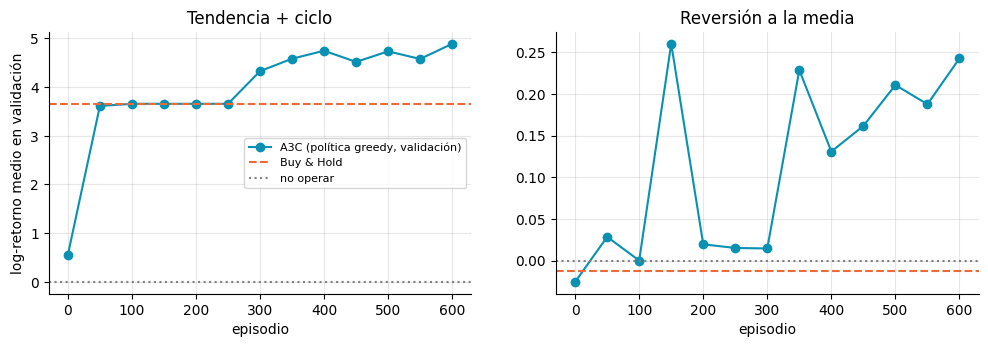

600 episodios por mercado, 4 trabajadores: 24 s de entrenamiento


In [6]:
VAL = val_sets()
HP_PRUEBA = dict(lr=1e-3, lr_final=0.1, gamma=0.9, hidden=64, n_steps=20, beta=0.01, beta_final=0.1)
n_prueba = 600
pruebas = entrenar_varios([tarea(g, HP_PRUEBA, n_prueba, 0, 50) for g in ["Tendencia + ciclo", "Reversión a la media"]], "comprobación")
curv = curvas_validacion(pruebas)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, run, c in zip(axs, pruebas, curv):
    g = run["gen"]
    ax.plot(run["snap_ep"], [c[j] for j in range(len(run["snap_ep"]))], "o-", color="#0891b2", label="A3C (política greedy, validación)")
    ax.axhline(evaluate(VAL[g], BASELINES["Buy & Hold"])["log_ret"].mean(), color="#ed6a37", ls="--", label="Buy & Hold")
    ax.axhline(0, color="gray", ls=":", label="no operar")
    ax.set_title(g)
    ax.set_xlabel("episodio")
axs[0].set_ylabel("log-retorno medio en validación")
axs[0].legend(fontsize=8)
plt.show()
print(f"{n_prueba} episodios por mercado, {WORKERS} trabajadores: {pruebas[0]['train_time']:.0f} s de entrenamiento")

### Qué esperamos antes de ajustar nada

Con lo aprendido en la práctica 1, con DQN y con la teoría, estas son las hipótesis que se contrastarán con los resultados (sección 9):

1. **Tendencia + ciclo** (señal fuerte de *momentum*): A3C debería aprender el mismo *momentum* con histéresis que el resto y empatar con ellos, y hacerlo en **pocos episodios**, porque la red generaliza entre tendencias parecidas.
2. **Reversión a la media** (señal débil, *contrarian*): la señal es de décimas de punto frente a un ruido del 1–2 % por paso. Un actor-crítico se apoya en un crítico que es solo una estimación, así que necesitará un $\gamma$ no nulo (con $\gamma = 0$ la ganancia de un paso no compensa la comisión de entrada, como le pasaba a Q-Learning) y esperamos una curva **más inestable** que la de los tabulares.
3. **Browniano y regímenes** (sin señal, o señal escondida en las colas): lo racional es no operar o casi. Una política estocástica con entropía **podría operar de más** por pura exploración, pero como se evalúa la política *greedy* esperamos que acabe quedándose fuera.
4. **Trabajadores:** más trabajadores deberían dar **menos tiempo de reloj** por episodio, pero con más desfase entre los gradientes y los parámetros. Con tan pocos parámetros y una señal tan ruidosa, esperamos que el desfase importe poco y que la ganancia de velocidad sea casi lineal mientras haya núcleos libres.
5. **Entropía:** sin entropía ($\beta = 0$) la política debería colapsar pronto a una acción y aprender peor; con mucha, quedarse demasiado aleatoria.
6. **Tiempo:** como DQN, cada episodio costará mucho más que en una tabla (una pasada de gradiente cada $n$ pasos), pero los trabajadores en paralelo lo reducirán en tiempo de reloj.

## 5. Protocolo de evaluación y *baselines*

Se usa **exactamente el de la práctica 1** (`trader_rl.py`):

- Cada política se ejecuta, **sin explorar**, sobre las mismas 100 series de test de cada mercado, que no se han usado para entrenar ni para elegir nada.
- **Métrica principal: log-retorno medio** del capital, $\overline{\ln(B_T/B_0)}$, que equivale al crecimiento geométrico. Se prefiere a la media del balance porque en *tendencia + ciclo* los capitales finales llegan a multiplicarse por cientos y unas pocas series dominarían la media. También se dan el retorno geométrico, el Sharpe, el *drawdown* máximo, el número de operaciones y el % de series en las que se gana a *buy & hold*.
- **Referencias:** agente aleatorio, *buy & hold*, no operar nunca y dos reglas fijas (*momentum*: dentro si la tendencia es positiva; *contrarian*: dentro si es negativa).
- **Convergencia:** el primer episodio a partir del cual la curva de validación (suavizada) ya no sale de una banda alrededor de su valor final. El tiempo en segundos es ese nº de episodios por el coste de un episodio, medido aparte con el ordenador en reposo (sección 7).

In [7]:
TEST = test_sets()
res_base, filas = {}, []
for g in GENS:
    for nombre, fabrica in BASELINES.items():
        res = evaluate(TEST[g], fabrica)
        res_base[(g, nombre)] = res
        filas.append(summarize(res, nombre, g))
base = pd.DataFrame(filas).set_index(["Generador", "Agente"])
display(base[["Log-ret. medio", "Ret. geométrico (%)", "Sharpe", "Max DD (%)", "Operaciones"]].round(3))

# Comprobación: con las mismas semillas, las referencias son idénticas a las de la práctica 1
prac1 = pd.read_csv(Path(PADRE) / "tabla_comparativa.csv").set_index(["Generador", "Agente"])
assert np.allclose(base["Log-ret. medio"], prac1.loc[base.index, "Log-ret. medio"], atol=1e-3), "las series de test no coinciden con las de la práctica 1"
print("OK: las referencias coinciden con las de la práctica 1 (mismas series de test).")

Log-ret. medio  Ret. geométrico (%)  \
Generador            Agente                                                    
Tendencia + ciclo    Aleatorio                    1.558              375.064   
                     Buy & Hold                   3.316             2655.989   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)             6.105            44704.614   
                     Contrarian (regla)          -2.973              -94.883   
Browniano            Aleatorio                   -0.187              -17.058   
                     Buy & Hold                  -0.062               -6.039   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.141              -13.135   
                     Contrarian (regla)          -0.159              -14.695   
Reversión a la media Aleatorio                   -0.169              -15.581   
                     Buy & Hold                  -0.005               -0.484   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.324              -27.707   
                     Contrarian (regla)           0.069                7.096   
Regímenes            Aleatorio                   -0.220              -19.734   
                     Buy & Hold                  -0.128              -11.981   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.126              -11.877   
                     Contrarian (regla)          -0.233              -20.796   

                                         Sharpe  Max DD (%)  Operaciones  
Generador            Agente                                               
Tendencia + ciclo    Aleatorio            1.270      80.419       164.26  
                     Buy & Hold           1.856      90.251         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)     3.098      60.429        92.59  
                     Contrarian (regla)  -0.772      95.330        92.37  
Browniano            Aleatorio           -0.311      36.044       164.26  
                     Buy & Hold           0.057      41.919         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)    -0.241      34.717       119.16  
                     Contrarian (regla)  -0.232      34.226       119.18  
Reversión a la media Aleatorio           -0.262      31.895       164.26  
                     Buy & Hold           0.154      25.678         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)    -0.627      36.937       125.95  
                     Contrarian (regla)   0.263      23.624       125.95  
Regímenes            Aleatorio           -0.423      35.366       164.26  
                     Buy & Hold          -0.043      43.733         1.00  
                     Siempre fuera        0.000       0.000         0.00  
                     Momentum (regla)    -0.225      32.118       116.54  
                     Contrarian (regla)  -0.405      36.555       116.30

OK: las referencias coinciden con las de la práctica 1 (mismas series de test).


## 6. Ajuste de hiperparámetros

Se ajustan **por separado para cada mercado** y **solo con las series de validación**; las de test no se tocan hasta la sección 7. El criterio es el log-retorno medio en validación de la política *greedy*. Como en las prácticas anteriores la curva oscila (a veces la política «se apaga» y deja de operar unos episodios), la puntuación de un entrenamiento es **la media de sus tres últimas evaluaciones**, no solo la última.

**Hiperparámetros** (en el vocabulario del enunciado: tasa de aprendizaje, exploración —aquí, la entropía—, $\gamma$ y nº de episodios):

| Hiperparámetro | Valores explorados |
|---|---|
| tasa de aprendizaje inicial `lr` (Adam) | entre $3\cdot10^{-4}$ y $3\cdot10^{-3}$, escala logarítmica |
| decaimiento `lr_final` (la tasa termina en `lr·lr_final`) | 1 (constante), 0,1 |
| descuento $\gamma$ | 0, 0,5, 0,9, 0,99 (cada valor aparece en 4 de las 16 configuraciones) |
| neuronas por capa oculta | 32, 64 |
| pasos por actualización $n$ | 5, 20, 50 |
| coeficiente de entropía $\beta$ | 0,001, 0,01, 0,05 |
| decaimiento de la entropía `beta_final` ($\beta$ termina en `beta·beta_final`) | 1 (constante), 0,1 |
| nº de trabajadores | 4 (fijo; se estudia en la sección 8) |
| nº de episodios | se fija con las curvas de aprendizaje (apartado 6.3) |

**Protocolo** (el mismo estilo que en SARSA y DQN):

1. **Búsqueda aleatoria** de 16 configuraciones (las mismas para los cuatro mercados) con un entrenamiento corto de 500 episodios y 2 semillas.
2. **Reevaluación** de las 2 mejores de cada mercado con el entrenamiento completo (1500 episodios) y semillas nuevas, para no quedarse con una configuración que ganó por azar en un entrenamiento corto.

In [8]:
CLAVES = ("lr", "lr_final", "gamma", "hidden", "n_steps", "beta", "beta_final")


def muestrear(n, seed=0):
    rng = random.Random(seed)
    gammas = [0.0, 0.5, 0.9, 0.99]
    return [{"id": i, "lr": float(round(10 ** rng.uniform(np.log10(3e-4), np.log10(3e-3)), 6)), "lr_final": rng.choice([1.0, 0.1]),
             "gamma": gammas[i % 4], "hidden": rng.choice([32, 64]), "n_steps": rng.choice([5, 20, 50]),
             "beta": rng.choice([0.001, 0.01, 0.05]), "beta_final": rng.choice([1.0, 0.1])} for i in range(n)]


configs = muestrear(N_CONFIGS)
params_de = lambda c: {k: c[k] for k in CLAVES}
display(pd.DataFrame(configs).set_index("id"))

,lr,lr_final,gamma,hidden,n_steps,beta,beta_final
id,,,,,,,
0,0.002097,0.1,0.00,32,20,0.050,0.1
1,0.000762,0.1,0.50,64,20,0.050,1.0
2,0.000959,0.1,0.90,32,5,0.050,0.1
3,0.002913,1.0,0.99,64,5,0.050,1.0
4,0.002377,0.1,0.00,64,50,0.001,0.1
5,0.000815,1.0,0.50,64,20,0.050,0.1
6,0.000346,1.0,0.90,32,50,0.010,1.0
7,0.001227,0.1,0.99,32,50,0.010,1.0
8,0.000466,1.0,0.00,32,5,0.050,0.1


### 6.1 Búsqueda aleatoria

In [9]:
f_busqueda = CACHE / "busqueda.csv"
if RECOMPUTE or not f_busqueda.exists():
    meta = [(g, c["id"], s) for g in GENS for c in configs for s in SEMILLAS_BUSQUEDA]
    runs_b = entrenar_varios([tarea(g, params_de(configs[c]), N_EP_BUSQUEDA, s, EVAL_BUSQUEDA) for g, c, s in meta], "búsqueda aleatoria")
    curv_b = curvas_validacion(runs_b, solo_ultimas=3)
    busqueda = pd.DataFrame([{"gen": g, "config": c, "semilla": s, "score": float(np.mean(list(cv.values()))),
                              "sin_operar": float(np.mean(list(cv.values()))) == 0.0}
                             for (g, c, s), cv in zip(meta, curv_b)])
    busqueda = busqueda.merge(pd.DataFrame(configs), left_on="config", right_on="id").drop(columns="id")
    busqueda.to_csv(f_busqueda, index=False)
else:
    busqueda = pd.read_csv(f_busqueda)

print(f"{len(busqueda)} entrenamientos. Porcentaje con puntuación exactamente 0 (no operan en validación):")
print(busqueda.groupby("gen").sin_operar.mean().mul(100).round(0).astype(int).to_string())

búsqueda aleatoria: 128 entrenamientos en 2451 s


128 entrenamientos. Porcentaje con puntuación exactamente 0 (no operan en validación):
gen
Browniano               72
Regímenes               78
Reversión a la media    31
Tendencia + ciclo        3


**Sensibilidad.** Puntuación media de las configuraciones agrupadas por el valor de cada hiperparámetro (cada fila es un mercado, con su propia escala vertical). La columna de `lr` agrupa los valores muestreados en cuartiles.

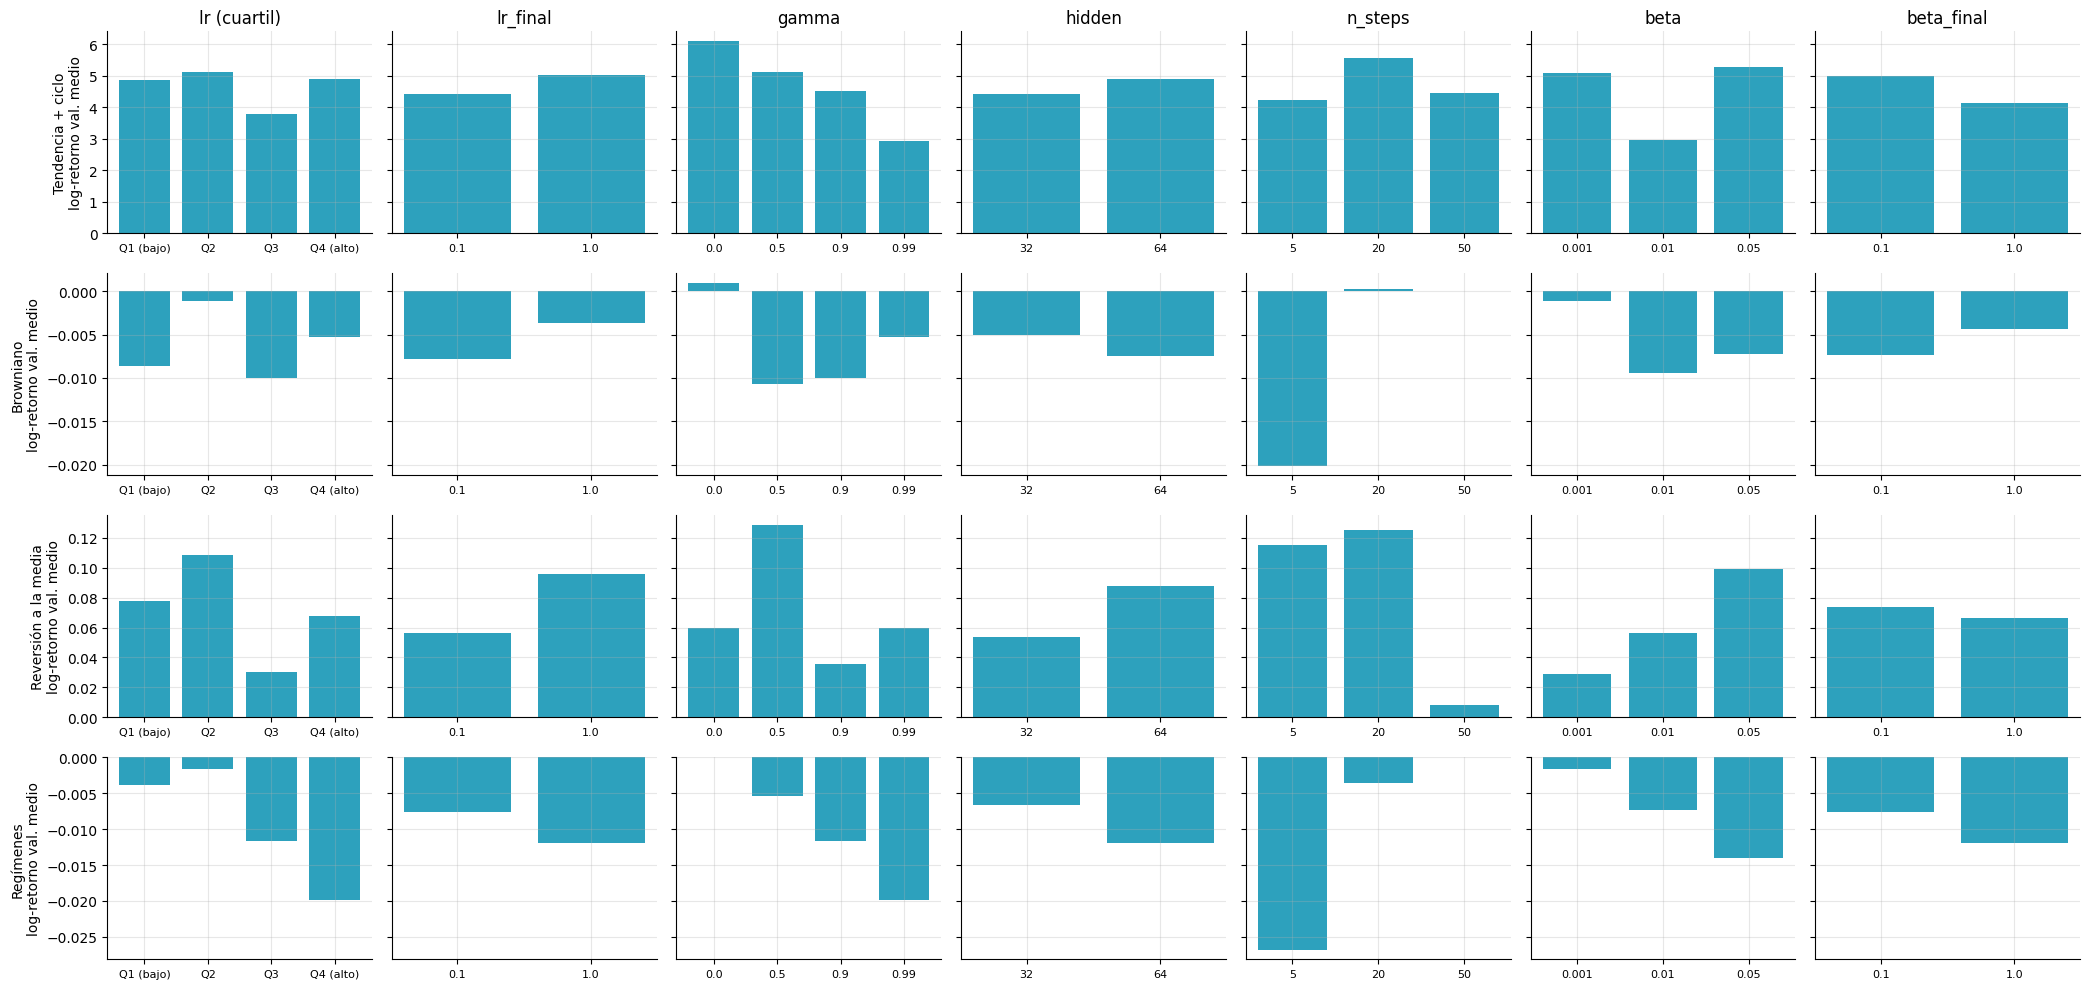

In [10]:
b = busqueda.copy()
b["lr (cuartil)"] = pd.qcut(b.lr.rank(method="first"), 4, labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])
columnas = ["lr (cuartil)", "lr_final", "gamma", "hidden", "n_steps", "beta", "beta_final"]
fig, axs = plt.subplots(len(GENS), len(columnas), figsize=(21, 10), sharey="row")
for i, g in enumerate(GENS):
    for j, col in enumerate(columnas):
        m = b[b.gen == g].groupby(col, observed=True).score.mean()
        axs[i, j].bar(range(len(m)), m.values, color="#0891b2", alpha=0.85)
        axs[i, j].set_xticks(range(len(m)))
        axs[i, j].set_xticklabels([str(x) for x in m.index], fontsize=8)
        if i == 0:
            axs[i, j].set_title(col)
        if j == 0:
            axs[i, j].set_ylabel(f"{g}\nlog-retorno val. medio")
plt.tight_layout()
plt.savefig(FIGS / "sensibilidad_busqueda.png", bbox_inches="tight")
plt.show()

### 6.2 Reevaluación de las mejores configuraciones

Las `TOP_K` mejores de cada mercado se reentrenan con el número de episodios del entrenamiento final y semillas nuevas. Se queda la de mayor puntuación media.

In [11]:
f_reeval, f_params = CACHE / "reevaluacion.csv", CACHE / "mejores_params.json"
if RECOMPUTE or not f_reeval.exists():
    ranking = busqueda.groupby(["gen", "config"]).score.mean().reset_index()
    top = ranking.sort_values(["gen", "score"], ascending=[True, False]).groupby("gen").head(TOP_K)
    meta = [(r.gen, int(r.config), s) for r in top.itertuples() for s in SEMILLAS_REEVAL]
    runs_r = entrenar_varios([tarea(g, params_de(configs[c]), N_EP_FINAL, s, EVAL_CADA) for g, c, s in meta], "reevaluación")
    curv_r = curvas_validacion(runs_r)
    filas, curvas = [], {}
    for (g, c, s), run, cv in zip(meta, runs_r, curv_r):
        v = [cv[j] for j in range(len(run["snap_ep"]))]
        filas.append({"gen": g, "config": c, "semilla": s, "score": float(np.mean(v[-3:]))})
        curvas.setdefault((g, c), []).append((run["snap_ep"], v))
    reeval = pd.DataFrame(filas).groupby(["gen", "config"]).score.mean().reset_index()
    reeval = reeval.merge(pd.DataFrame(configs), left_on="config", right_on="id").drop(columns="id")
    reeval.to_csv(f_reeval, index=False)
    dump({k: {"ep": v[0][0], "val": np.mean([x[1] for x in v], 0)} for k, v in curvas.items()}, CACHE / "curvas_reeval.joblib")
    elegida = reeval.sort_values("score", ascending=False, kind="stable").groupby("gen").head(1)
    MEJORES_PARAMS = {r.gen: {k: (int(getattr(r, k)) if k in ("hidden", "n_steps") else float(getattr(r, k))) for k in CLAVES} for r in elegida.itertuples()}
    json.dump(MEJORES_PARAMS, open(f_params, "w", encoding="utf-8"), indent=1, ensure_ascii=False)
else:
    reeval = pd.read_csv(f_reeval)
    MEJORES_PARAMS = json.load(open(f_params, encoding="utf-8"))
display(reeval.sort_values(["gen", "score"], ascending=[True, False]).reset_index(drop=True).round(4))
print("\nHiperparámetros elegidos:")
display(pd.DataFrame(MEJORES_PARAMS).T[list(CLAVES)].astype({"hidden": int, "n_steps": int}))

reevaluación: 16 entrenamientos en 714 s


,gen,config,score,lr,lr_final,gamma,hidden,n_steps,beta,beta_final
0,Browniano,15,0.0218,0.0024,0.1,0.99,64,20,0.01,0.1
1,Browniano,8,0.0000,0.0005,1.0,0.00,32,5,0.05,0.1
2,Regímenes,0,0.0000,0.0021,0.1,0.00,32,20,0.05,0.1
3,Regímenes,1,0.0000,0.0008,0.1,0.50,64,20,0.05,1.0
4,Reversión a la media,8,0.2156,0.0005,1.0,0.00,32,5,0.05,0.1
5,Reversión a la media,1,0.1787,0.0008,0.1,0.50,64,20,0.05,1.0
6,Tendencia + ciclo,5,6.3115,0.0008,1.0,0.50,64,20,0.05,0.1
7,Tendencia + ciclo,0,6.1501,0.0021,0.1,0.00,32,20,0.05,0.1



Hiperparámetros elegidos:


,lr,lr_final,gamma,hidden,n_steps,beta,beta_final
Tendencia + ciclo,0.000815,1.0,0.50,64,20,0.05,0.1
Reversión a la media,0.000466,1.0,0.00,32,5,0.05,0.1
Browniano,0.002356,0.1,0.99,64,20,0.01,0.1
Regímenes,0.002097,0.1,0.00,32,20,0.05,0.1


### 6.3 Curvas de reevaluación y número de episodios

Curvas de validación de las `TOP_K` mejores configuraciones de cada mercado (media de 2 semillas). Sirven para decidir cuántos episodios hacen falta: el entrenamiento final usa `N_EP_FINAL` episodios.

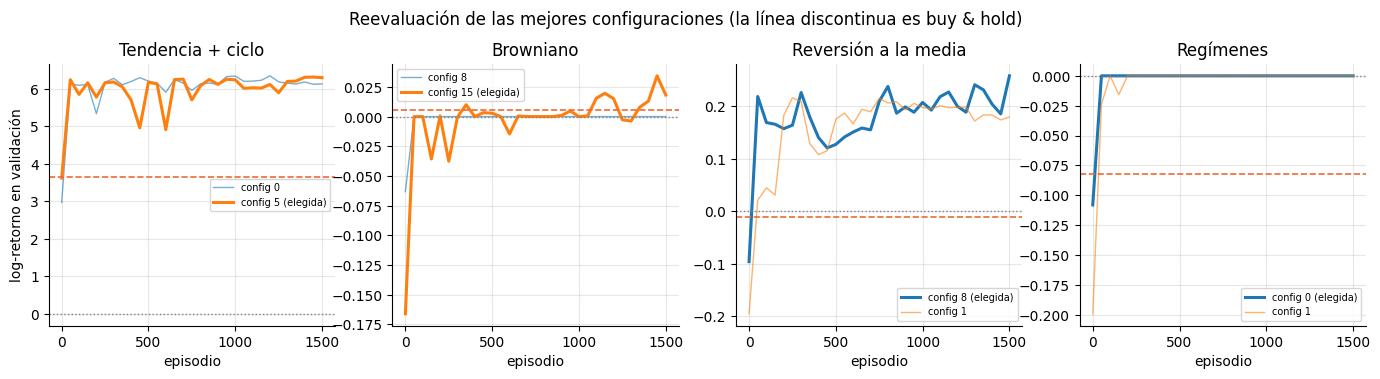

In [12]:
curvas = load(CACHE / "curvas_reeval.joblib")
fig, axs = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, g in zip(axs, GENS):
    for (gg, c), v in curvas.items():
        if gg == g:
            elegido = MEJORES_PARAMS[g]["lr"] == configs[c]["lr"]
            ax.plot(v["ep"], v["val"], lw=2.2 if elegido else 1, alpha=1 if elegido else 0.6, label=f"config {c}" + (" (elegida)" if elegido else ""))
    ax.axhline(evaluate(VAL[g], BASELINES["Buy & Hold"])["log_ret"].mean(), color="#ed6a37", ls="--", lw=1.2)
    ax.axhline(0, color="gray", ls=":", lw=1)
    ax.set_title(g)
    ax.set_xlabel("episodio")
    ax.legend(fontsize=7)
axs[0].set_ylabel("log-retorno en validación")
fig.suptitle("Reevaluación de las mejores configuraciones (la línea discontinua es buy & hold)", y=1.04)
plt.savefig(FIGS / "curvas_reevaluacion.png", bbox_inches="tight")
plt.show()

**Conclusiones del ajuste de hiperparámetros**

- **En los mercados sin señal la búsqueda no distingue nada.** De 128 entrenamientos, el 72 % en *browniano* y el 78 % en *regímenes* terminan sin operar nunca (puntuación exactamente 0), y el resto rinde unas milésimas por encima o por debajo de 0. Los hiperparámetros «elegidos» ahí son un desempate casi arbitrario (en *browniano*, la mejor configuración puntúa 0,022, que es ruido).
- **Tendencia + ciclo: γ bajo.** La puntuación media en validación baja de forma monótona con γ (6,11 con γ = 0; 5,11 con 0,5; 4,51 con 0,9; 2,92 con 0,99). La tendencia predice los retornos inmediatos, y un γ alto solo añade varianza al crítico. Las dos mejores configuraciones tienen γ = 0 y γ = 0,5 y rinden casi igual (6,15 y 6,31 al reevaluarlas).
- **Reversión a la media: γ = 0 funciona.** Es lo contrario de lo que esperábamos (hipótesis 2): la mejor configuración reevaluada (0,216) tiene γ = 0 y `n_steps` = 5, y la segunda (0,179) γ = 0,5. En media sobre toda la búsqueda, γ = 0,5 es el mejor valor (0,129) y `n_steps` = 50 el peor (0,008): un horizonte largo mete mucho ruido en un retorno cuya señal es de décimas de punto.
- **Entropía.** En reversión, más β es mejor en media (0,03 con 0,001; 0,06 con 0,01; 0,10 con 0,05) y las dos configuraciones elegidas usan β = 0,05. En el resto la diferencia es de ruido.
- **Tamaño de la red** (32 o 64 neuronas) y **`beta_final`** no marcan diferencias claras.

## 7. Entrenamiento final, curvas de aprendizaje y resultados en test

Con los hiperparámetros elegidos en cada mercado se entrena A3C con **5 semillas independientes** y `N_EP_FINAL` episodios cada una, y se evalúa la política *greedy* en validación cada `EVAL_CADA` episodios.

In [13]:
f_final = CACHE / "runs_final.joblib"
if RECOMPUTE or not f_final.exists():
    RUNS = entrenar_varios([tarea(g, MEJORES_PARAMS[g], N_EP_FINAL, s, EVAL_CADA) for g in GENS for s in SEMILLAS_FINAL], "entrenamiento final")
    curv = curvas_validacion(RUNS)
    for r, cv in zip(RUNS, curv):
        r["val"] = [cv[j] for j in range(len(r["snap_ep"]))]
    dump(RUNS, f_final)
else:
    RUNS = load(f_final)
runs_de = lambda g, runs=None: [r for r in (runs or RUNS) if r["gen"] == g]
print(f"{len(RUNS)} entrenamientos finales ({len(GENS)} mercados × {len(SEMILLAS_FINAL)} semillas, {N_EP_FINAL} episodios, {WORKERS} trabajadores)")

entrenamiento final: 20 entrenamientos en 874 s


20 entrenamientos finales (4 mercados × 5 semillas, 1500 episodios, 4 trabajadores)


**Coste por episodio.** Los tiempos de los entrenamientos que se lanzan a la vez no se pueden comparar (compiten por los núcleos). Como en las prácticas anteriores, se mide aparte, **con el ordenador en reposo**, cuánto tarda un episodio, sin evaluar y sin contar el arranque de los procesos. Se dan dos cifras para cada nº de trabajadores:

- **Tiempo de reloj por episodio** (`ms/episodio`): lo que se espera al entrenar. Baja al añadir trabajadores mientras haya núcleos libres.
- **Tiempo de CPU por episodio** (`ms CPU/episodio` = trabajadores × reloj): el trabajo total. Es la cifra comparable con los algoritmos de un solo proceso (tabulares y DQN).

El tiempo hasta convergencia es el coste por el nº de episodios que se tarda en converger.

In [14]:
def coste_a3c(gen, hp, workers, n_ep=N_EP_COSTE, repeticiones=REP_COSTE):
    """ms de reloj por episodio (mínimo de varias medidas, por si el sistema hace otra cosa en ese momento)."""
    return 1000 * min(A.train_a3c(gen, hp, n_ep, 900, workers=workers, eval_every=n_ep, escalas=ESCALAS[gen])["train_time"]
                      for _ in range(repeticiones)) / n_ep


WORKERS_ABL = (1, 2, 4, 8)
f_coste = CACHE / "coste_ms.csv"
if RECOMPUTE or not f_coste.exists():
    coste = pd.DataFrame([{"workers": w, "gen": g, "ms": coste_a3c(g, MEJORES_PARAMS[g], w)} for w in WORKERS_ABL for g in GENS])
    coste.to_csv(f_coste, index=False)
else:
    coste = pd.read_csv(f_coste)
COSTE = {(r.workers, r.gen): r.ms for r in coste.itertuples()}
tc = coste.pivot(index="gen", columns="workers", values="ms").loc[GENS]
tc.columns = [f"{w} trab." for w in tc.columns]
display(tc.round(0).rename_axis("ms de reloj por episodio"))
tcpu = coste.assign(cpu=coste.ms * coste.workers).pivot(index="gen", columns="workers", values="cpu").loc[GENS]
tcpu.columns = [f"{w} trab." for w in tcpu.columns]
display(tcpu.round(0).rename_axis("ms de CPU por episodio (trabajadores × reloj)"))

,1 trab.,2 trab.,4 trab.,8 trab.
ms de reloj por episodio,,,,
Tendencia + ciclo,48.0,29.0,25.0,27.0
Browniano,48.0,29.0,25.0,28.0
Reversión a la media,144.0,86.0,67.0,61.0
Regímenes,47.0,29.0,28.0,26.0


,1 trab.,2 trab.,4 trab.,8 trab.
ms de CPU por episodio (trabajadores × reloj),,,,
Tendencia + ciclo,48.0,58.0,99.0,217.0
Browniano,48.0,57.0,99.0,225.0
Reversión a la media,144.0,171.0,269.0,489.0
Regímenes,47.0,57.0,110.0,210.0


### Curvas de aprendizaje

Log-retorno medio de la política *greedy* en validación (media de las 5 semillas y rango). Las líneas verticales punteadas marcan el episodio de convergencia (mediana de las semillas).

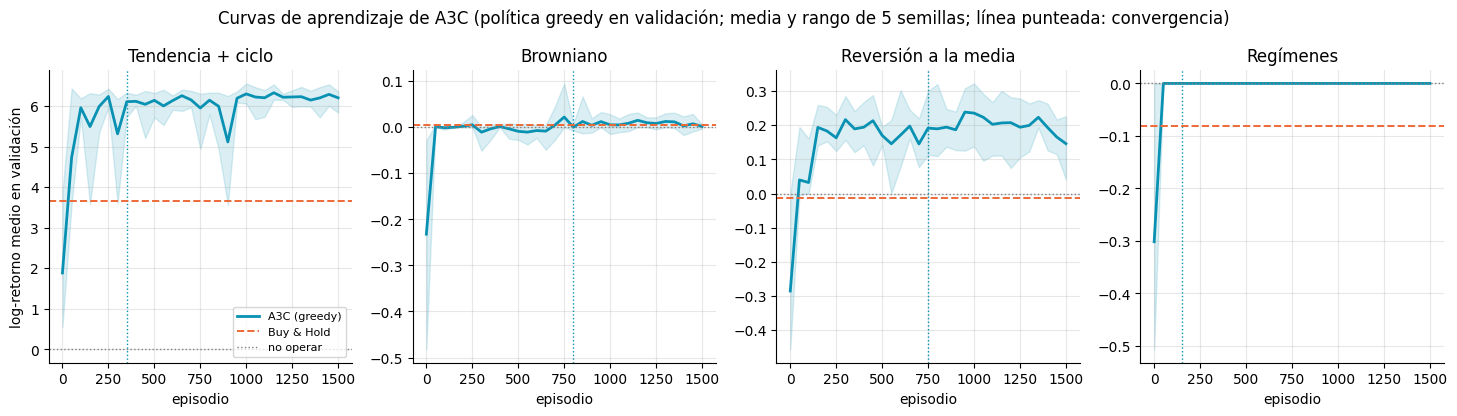

In [15]:
def conv_de(runs):
    return float(np.median([convergence_episode(list(r["snap_ep"]), r["val"]) for r in runs]))


fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, g in zip(axs, GENS):
    rs = runs_de(g)
    val = np.array([r["val"] for r in rs])
    ep = rs[0]["snap_ep"]
    ax.plot(ep, val.mean(0), color="#0891b2", lw=2, label="A3C (greedy)")
    ax.fill_between(ep, val.min(0), val.max(0), color="#0891b2", alpha=0.15)
    ax.axvline(conv_de(rs), color="#0891b2", ls=":", lw=1)
    ax.axhline(evaluate(VAL[g], BASELINES["Buy & Hold"])["log_ret"].mean(), color="#ed6a37", ls="--", lw=1.4, label="Buy & Hold")
    ax.axhline(0, color="gray", ls=":", lw=1, label="no operar")
    ax.set_title(g)
    ax.set_xlabel("episodio")
axs[0].set_ylabel("log-retorno medio en validación")
axs[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Curvas de aprendizaje de A3C (política greedy en validación; media y rango de 5 semillas; línea punteada: convergencia)", y=1.04)
plt.savefig(FIGS / "curvas_aprendizaje.png", bbox_inches="tight")
plt.show()

### Evaluación en test y tabla comparativa

Cada agente entrenado (la red final) se evalúa, sin explorar, en las **100 series de test** del mercado (las mismas que en la práctica 1). Las cifras son la media de 5 semillas × 100 series; la desviación entre semillas mide cuánto cambia el log-retorno medio de una semilla a otra.

In [16]:
def evaluar_finales(runs, estocastica=False):
    """Evalúa la última instantánea (la red final) de cada entrenamiento en test, en paralelo."""
    return Parallel(n_jobs=N_CORES, max_nbytes=None)(delayed(_eval_job)(r, len(r["snap_ep"]) - 1, "test", estocastica) for r in runs)


def fila(res_list, nombre, g, runs=None, workers=WORKERS):
    res = pd.concat(res_list, ignore_index=True)
    bh = res_base[(g, "Buy & Hold")]["log_ret"].values
    extra = {"% series > B&H": 100 * np.mean(res["log_ret"].values > np.tile(bh, len(res) // len(bh)))}
    if runs is not None:
        conv = float(np.median([convergence_episode(list(r["snap_ep"]), r["val"]) for r in runs]))
        ms = COSTE[(workers, g)]
        extra.update({"Std log-ret. entre semillas": float(np.std([d["log_ret"].mean() for d in res_list])),
                      "Episodios hasta convergencia": conv, "ms/episodio": ms, "ms CPU/episodio": ms * workers,
                      "Tiempo hasta convergencia (s)": conv * ms / 1000, "Tiempo CPU hasta convergencia (s)": conv * ms * workers / 1000})
    return summarize(res, nombre, g, extra)


t0 = time.perf_counter()
EVAL_RUNS = evaluar_finales(RUNS)
print(f"{len(RUNS)} evaluaciones en test en {time.perf_counter() - t0:.0f} s")

filas = [{**summarize(res_base[(g, n)], n, g), "% series > B&H": 100 * np.mean(res_base[(g, n)]["log_ret"].values > res_base[(g, "Buy & Hold")]["log_ret"].values)}
         for g in GENS for n in BASELINES]
for g in GENS:
    idx = [i for i, r in enumerate(RUNS) if r["gen"] == g]
    filas.append(fila([EVAL_RUNS[i] for i in idx], "A3C", g, [RUNS[i] for i in idx]))
tabla = pd.DataFrame(filas).set_index(["Generador", "Agente"])

FMT = {"Log-ret. medio": "{:.3f}", "Ret. geométrico (%)": "{:,.1f}", "Ret. mediano (%)": "{:,.1f}", "% series > B&H": "{:.0f}", "Sharpe": "{:.2f}", "Max DD (%)": "{:.1f}",
       "Operaciones": "{:.1f}", "% tiempo invertido": "{:.1f}", "Std log-ret. entre semillas": "{:.3f}", "Episodios hasta convergencia": "{:.0f}",
       "ms/episodio": "{:.0f}", "ms CPU/episodio": "{:.0f}", "Tiempo hasta convergencia (s)": "{:.1f}", "Tiempo CPU hasta convergencia (s)": "{:.1f}"}
COLS = ["Log-ret. medio", "Ret. geométrico (%)", "% series > B&H", "Sharpe", "Max DD (%)", "Operaciones", "% tiempo invertido", "Std log-ret. entre semillas",
        "Episodios hasta convergencia", "ms/episodio", "ms CPU/episodio", "Tiempo hasta convergencia (s)", "Tiempo CPU hasta convergencia (s)"]
ORDEN = ["A3C", "Buy & Hold", "Aleatorio", "Siempre fuera", "Momentum (regla)", "Contrarian (regla)"]
principal = tabla.loc[[(g, a) for g in GENS for a in ORDEN], COLS]
display(principal.style.format(FMT, na_rep="—"))

20 evaluaciones en test en 21 s


### Comparación con los algoritmos de la práctica 1 y con DQN

Mismas series de test y mismas métricas (`../tabla_comparativa.csv` y `resultados_dqn.csv`). Hay que tener en cuenta que los tabulares se entrenaron 3000 episodios, DQN 200 y A3C `N_EP_FINAL`; y que los tiempos por episodio son de naturaleza distinta (un proceso en los tabulares y DQN; varios en A3C).

Log-retorno medio en test (entre paréntesis, desviación entre semillas):


,Q-Learning,SARSA,Monte Carlo,DQN,Doble DQN,A3C,Buy & Hold,Aleatorio
Tendencia + ciclo,+6.338 (±0.102),+6.316 (±0.234),+6.522 (±0.039),+6.092 (±0.182),+6.241 (±0.101),+6.412 (±0.189),+3.316,+1.558
Browniano,+0.000 (±0.000),+0.000 (±0.000),-0.012 (±0.025),-0.005 (±0.010),-0.005 (±0.010),-0.073 (±0.039),-0.062,-0.187
Reversión a la media,+0.155 (±0.042),+0.203 (±0.025),+0.238 (±0.015),+0.175 (±0.045),+0.201 (±0.020),+0.114 (±0.044),-0.005,-0.169
Regímenes,+0.040 (±0.022),+0.000 (±0.000),+0.031 (±0.011),+0.030 (±0.040),+0.008 (±0.011),+0.000 (±0.000),-0.128,-0.220


Convergencia (episodios / segundos de reloj):


,Q-Learning,SARSA,Monte Carlo,DQN,Doble DQN,A3C
Tendencia + ciclo,300 ep. / 2.4 s,500 ep. / 4.0 s,500 ep. / 4.8 s,60 ep. / 9.1 s,60 ep. / 9.2 s,350 ep. / 8.6 s (34.6 s CPU)
Browniano,400 ep. / 4.2 s,1700 ep. / 13.0 s,700 ep. / 6.5 s,80 ep. / 10.7 s,80 ep. / 11.0 s,800 ep. / 19.8 s (79.4 s CPU)
Reversión a la media,2200 ep. / 18.6 s,1600 ep. / 14.1 s,1600 ep. / 17.3 s,160 ep. / 23.3 s,180 ep. / 29.0 s,750 ep. / 50.5 s (202.1 s CPU)
Regímenes,2000 ep. / 16.6 s,600 ep. / 5.5 s,1300 ep. / 11.5 s,140 ep. / 18.8 s,180 ep. / 26.4 s,150 ep. / 4.1 s (16.5 s CPU)


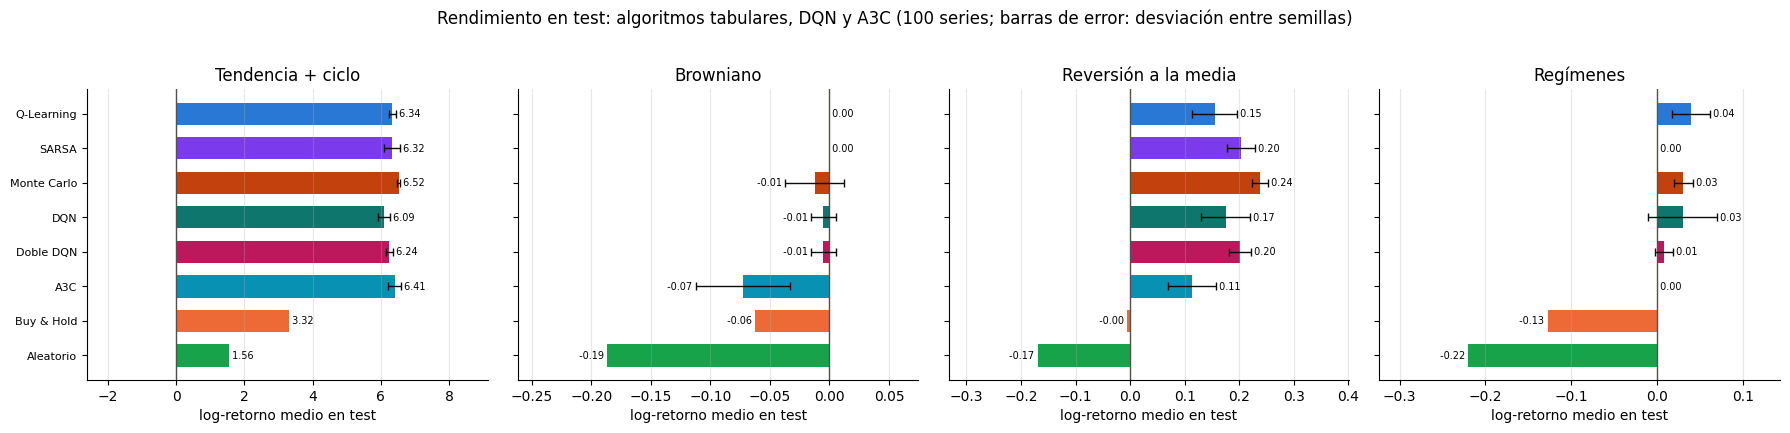

In [17]:
dqn = pd.read_csv("resultados_dqn.csv").set_index(["Generador", "Agente"])
TABULARES, DQNS = ["Q-Learning", "SARSA", "Monte Carlo"], ["DQN", "Doble DQN"]
ALGOS = TABULARES + DQNS + ["A3C"]
log_ret = lambda g, a: (principal if a == "A3C" else dqn if a in DQNS else prac1).loc[(g, a), "Log-ret. medio"]
std = lambda g, a: (principal if a == "A3C" else dqn if a in DQNS else prac1).loc[(g, a), "Std log-ret. entre semillas"]
resumen = pd.DataFrame({a: [f"{log_ret(g, a):+.3f} (±{std(g, a):.3f})" for g in GENS] for a in ALGOS}, index=GENS)
resumen["Buy & Hold"] = [f"{principal.loc[(g, 'Buy & Hold'), 'Log-ret. medio']:+.3f}" for g in GENS]
resumen["Aleatorio"] = [f"{principal.loc[(g, 'Aleatorio'), 'Log-ret. medio']:+.3f}" for g in GENS]
print("Log-retorno medio en test (entre paréntesis, desviación entre semillas):")
display(resumen)

ms_de = lambda g, a: (principal.loc[(g, a), "ms/episodio"] if a == "A3C" else (dqn if a in DQNS else prac1).loc[(g, a), "ms/episodio"])
cpu_de = lambda g, a: principal.loc[(g, a), "ms CPU/episodio"] if a == "A3C" else ms_de(g, a)
src = lambda a: principal if a == "A3C" else dqn if a in DQNS else prac1
conv = pd.DataFrame({a: [f"{src(a).loc[(g, a), 'Episodios hasta convergencia']:.0f} ep. / {src(a).loc[(g, a), 'Episodios hasta convergencia'] * ms_de(g, a) / 1000:.1f} s"
                         + (f" ({src(a).loc[(g, a), 'Episodios hasta convergencia'] * cpu_de(g, a) / 1000:.1f} s CPU)" if a == "A3C" else "") for g in GENS] for a in ALGOS}, index=GENS)
print("Convergencia (episodios / segundos de reloj):")
display(conv)

COLORES = {"A3C": "#0891b2", "DQN": "#0f766e", "Doble DQN": "#be185d", "Q-Learning": "#2a78d6", "SARSA": "#7c3aed", "Monte Carlo": "#c2410c",
           "Buy & Hold": "#ed6a37", "Aleatorio": "#16a34a", "Q-Learning (estado ampliado)": "#6250d6", "A3C (estado ampliado)": "#0e7490"}
fig, axs = plt.subplots(1, 4, figsize=(18, 4.2))
mostrar = ALGOS + ["Buy & Hold", "Aleatorio"]
for ax, g in zip(axs, GENS):
    vals = [log_ret(g, a) if a in ALGOS else principal.loc[(g, a), "Log-ret. medio"] for a in mostrar]
    errs = [std(g, a) if a in ALGOS else 0 for a in mostrar]
    ax.barh(range(len(mostrar)), vals, color=[COLORES[a] for a in mostrar], height=0.65)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(range(len(mostrar)), mostrar if g == GENS[0] else [""] * len(mostrar), fontsize=8)
    ax.invert_yaxis()
    ax.set_title(g)
    ax.set_xlabel("log-retorno medio en test")
    for k, (v, e) in enumerate(zip(vals, errs)):
        if e > 0:
            ax.errorbar(v, k, xerr=e, fmt="none", ecolor="#0b0b0b", capsize=3, lw=1)
        ax.text(v + e if v >= 0 else v - e, k, f" {v:.2f} ", va="center", ha="left" if v >= 0 else "right", fontsize=7)
    lo, hi = min(0, min(vals)), max(0, max(vals))
    pad = 0.4 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)
    ax.grid(axis="y", visible=False)
fig.suptitle("Rendimiento en test: algoritmos tabulares, DQN y A3C (100 series; barras de error: desviación entre semillas)", y=1.02)
plt.tight_layout()
plt.savefig(FIGS / "comparativa.png", bbox_inches="tight")
plt.show()

**Análisis de los resultados en test (A3C, 5 semillas × 100 series)**

- **Tendencia + ciclo.** A3C obtiene 6,41 (±0,19 entre semillas) frente a 3,32 de *buy & hold* (supera a B&H en el 98 % de las series) y 6,10 de la regla de *momentum*. Opera unas 30 veces por serie frente a las 93 de la regla: ha aprendido el *momentum* **con histéresis** (sección 8.1). Es el mejor resultado de los dos algoritmos con red (DQN 6,09 / Doble DQN 6,24), pero queda por debajo de Monte Carlo (6,52) y es bastante más inestable entre semillas (±0,19 frente a ±0,04).
- **Browniano.** A3C **no consigue quedarse fuera**: −0,073 (±0,04), peor que no operar (0) y que Q-Learning y SARSA, que acaban exactamente en 0. Sigue invertido el 74 % del tiempo y opera 14 veces por serie. La configuración «elegida» (γ = 0,99) se escogió por una puntuación de ruido (0,022 en validación): la búsqueda no tenía de dónde aprender.
- **Reversión a la media.** A3C gana 0,114 (+12 % geométrico) frente a −0,005 de B&H y supera a B&H en el 75 % de las series, pero queda por debajo de todos los demás agentes entrenados (Q-Learning 0,155; SARSA 0,203; Monte Carlo 0,238; DQN 0,175; Doble DQN 0,201). Es el mercado donde la curva de validación es más ruidosa y donde más cuesta cada episodio.
- **Regímenes.** A3C acaba **sin operar** (0,000, igual que SARSA): la política es «fuera» para todas las tendencias. No pierde, pero tampoco aprende la pequeña ganancia que sí sacan Q-Learning (+0,040) y Monte Carlo (+0,031).
- **Convergencia.** Hacen falta 350 episodios en *tendencia + ciclo*, 800 en *browniano* y 750 en *reversión*; en *regímenes* los 150 son un artefacto, porque la curva queda en 0 desde que el agente deja de operar. Es **más que DQN** (60–180 episodios), del orden de los tabulares en el mercado fácil y menos que ellos en reversión (750 frente a 1600–2200). Con 4 trabajadores, A3C cuesta 25 ms de reloj por episodio en los mercados rápidos y 67 ms en *reversión* (red de 32 neuronas con `n_steps` = 5: muchas más actualizaciones por episodio), con 99–269 ms de CPU por episodio, comparable a DQN (134–204 ms).

## 8. Análisis

### 8.1 Política aprendida: ¿es la estrategia esperada?

Para cada nivel de tendencia y según la posición actual, se muestra la fracción de las 5 semillas que **quedan invertidas tras actuar** con la política *greedy*: estando fuera, eso significa comprar; estando dentro, no vender (verde oscuro = las 5 semillas; blanco = ninguna). Es la misma figura que en las prácticas anteriores: el hueco entre las filas «fuera» y «dentro» es la **histéresis**.

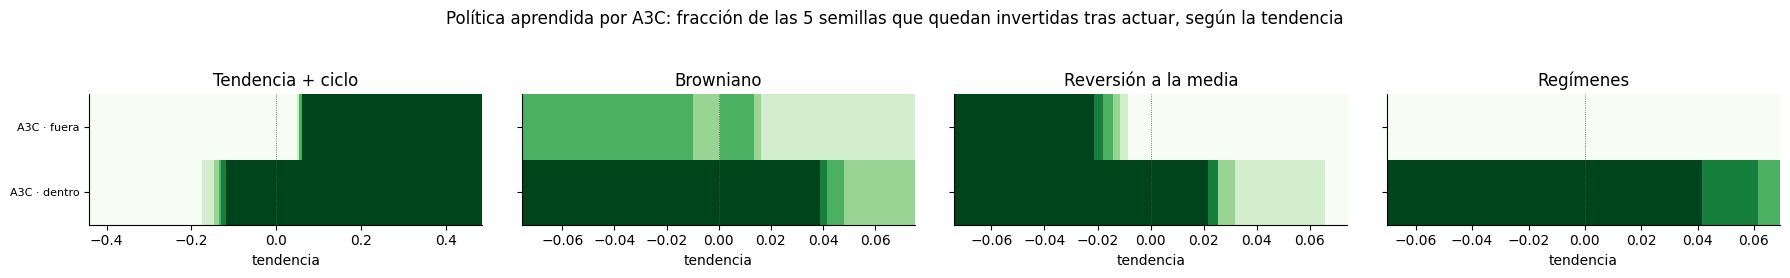

In [18]:
def mapa_politica(runs, g):
    mu, sd = ESCALAS[g][0][0], ESCALAS[g][1][0]
    xs = np.linspace(mu - 3 * sd, mu + 3 * sd, 161)
    pols = [A.politica_de(r, len(r["snap_ep"]) - 1) for r in runs]
    M = []
    for pos in (0, 1):
        acts = np.array([[p(np.array([t, pos], dtype=np.float32)) for t in xs] for p in pols])
        M.append(((acts == 2) if pos == 0 else (acts != 0)).mean(0))
    return xs, np.array(M)


fig, axs = plt.subplots(1, 4, figsize=(18, 2.6))
for ax, g in zip(axs, GENS):
    xs, M = mapa_politica(runs_de(g), g)
    dx = xs[1] - xs[0]
    ax.pcolormesh(np.append(xs - dx / 2, xs[-1] + dx / 2), np.arange(3), M, cmap="Greens", vmin=0, vmax=1, shading="flat")
    ax.axvline(0, color="#52514e", lw=0.6, ls=":")
    ax.set_ylim(2, 0)
    ax.set_yticks([0.5, 1.5], ["A3C · fuera", "A3C · dentro"] if g == GENS[0] else ["", ""], fontsize=8)
    ax.set_title(g)
    ax.set_xlabel("tendencia")
    ax.grid(False)
fig.suptitle("Política aprendida por A3C: fracción de las 5 semillas que quedan invertidas tras actuar, según la tendencia", y=1.05)
plt.tight_layout()
plt.savefig(FIGS / "politicas.png", bbox_inches="tight")
plt.show()

**Un episodio de test de ejemplo** por mercado (serie 0, semilla 0). Los puntos verdes indican que el agente está invertido y los rojos que está fuera. El panel inferior compara su capital con el de *buy & hold* (en escala logarítmica en *tendencia + ciclo*).

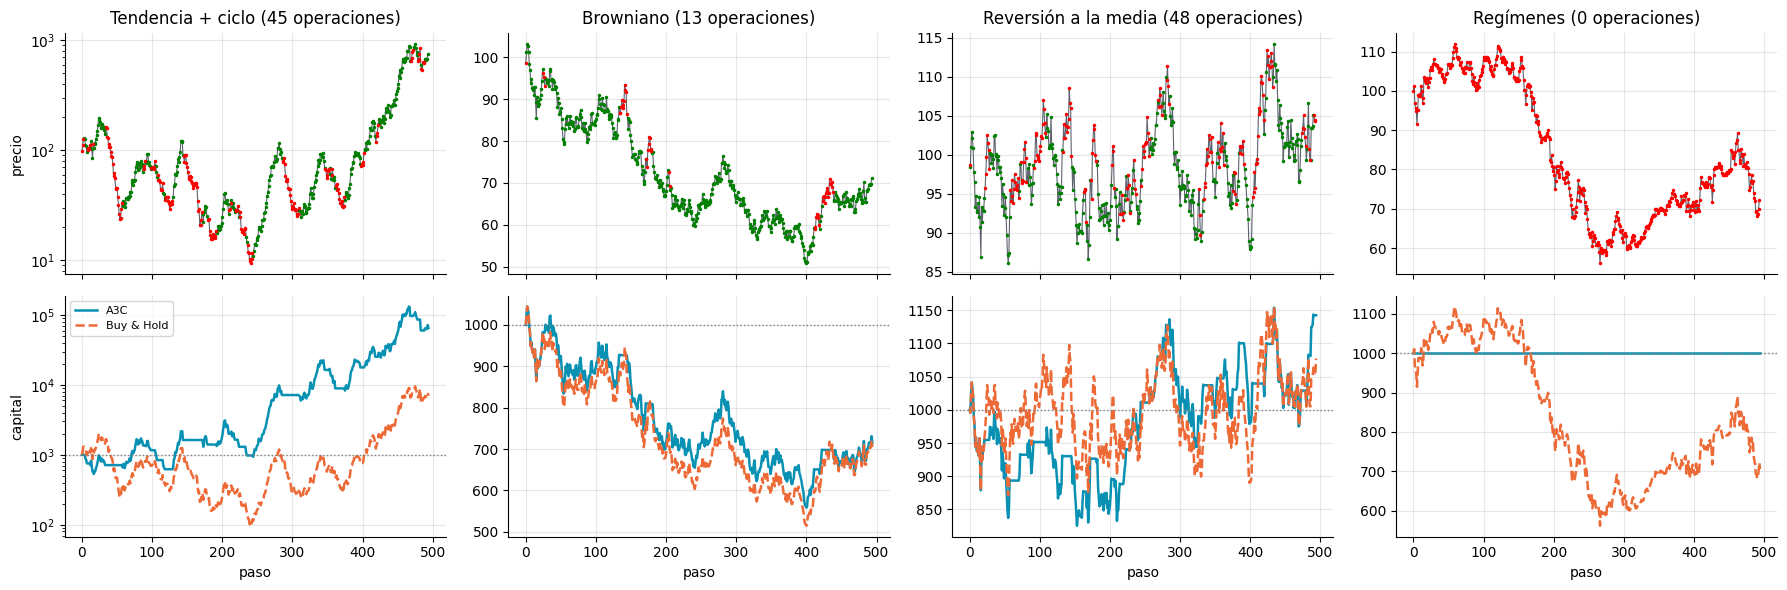

In [19]:
fig, axs = plt.subplots(2, 4, figsize=(18, 6), sharex=True)
for k, g in enumerate(GENS):
    prices = TEST[g][0]
    run = runs_de(g)[0]
    bal, pos, ops = run_episode(prices, A.politica_de(run, len(run["snap_ep"]) - 1))
    bal_bh, _, _ = run_episode(prices, BASELINES["Buy & Hold"](0))
    p = prices[5:-1]
    axs[0, k].plot(p, color="#1b2433", lw=0.8, alpha=0.7)
    axs[0, k].plot(np.where(pos == 1, p, np.nan), ".", color="green", ms=3)
    axs[0, k].plot(np.where(pos == 0, p, np.nan), ".", color="red", ms=3)
    axs[0, k].set_title(f"{g} ({ops} operaciones)")
    axs[1, k].plot(bal, color=COLORES["A3C"], lw=1.8, label="A3C")
    axs[1, k].plot(bal_bh, color=COLORES["Buy & Hold"], lw=1.8, ls="--", label="Buy & Hold")
    axs[1, k].axhline(1000, color="gray", ls=":", lw=1)
    axs[1, k].set_xlabel("paso")
    if g == "Tendencia + ciclo":
        axs[0, k].set_yscale("log")
        axs[1, k].set_yscale("log")
axs[0, 0].set_ylabel("precio")
axs[1, 0].set_ylabel("capital")
axs[1, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGS / "episodios_ejemplo.png", bbox_inches="tight")
plt.show()

**Lectura de la política.** En *tendencia + ciclo* aparece un *momentum* con histéresis claro y estable en las 5 semillas: estando fuera, se compra con tendencia > 0,06; estando dentro, se mantiene hasta ≈ −0,13. En *reversión a la media* es el *contrarian* con histéresis esperado: se compra tras caídas (tendencia < −0,02) y se mantiene hasta que la tendencia pasa de ≈ +0,02, con cierta discrepancia entre semillas en los bordes. En *regímenes* la fila «fuera» está vacía: nunca compra. En *browniano* la política es un mosaico sin patrón (las semillas no coinciden), como cabe esperar de aprender ruido.

### 8.2 Número de trabajadores asíncronos

La idea de A3C es que varios trabajadores jugando en paralelo (a) decorrelacionan los datos sin memoria de experiencias y (b) reducen el tiempo de entrenamiento. Se entrena con 1, 2, 4 y 8 trabajadores (con los hiperparámetros elegidos y el **mismo nº total de episodios**, `N_EP_EXTRA`) y se mira cómo cambian el rendimiento, los episodios hasta converger y el tiempo. **Con un solo trabajador A3C se reduce a un actor-crítico de $n$ pasos síncrono** (lo que se suele llamar A2C con un entorno), así que esta comparación aísla el efecto de lo asíncrono.

trabajadores: 32 entrenamientos en 1023 s


trabajadores,1,2,4,8
log-retorno en test,,,,
Tendencia + ciclo,6.084,6.319,6.195,6.477
Browniano,-0.062,-0.032,-0.036,-0.033
Reversión a la media,0.161,0.156,0.119,0.167
Regímenes,0.000,0.000,0.000,0.000


trabajadores,1,2,4,8
episodios hasta converger,,,,
Tendencia + ciclo,500.0,450.0,350.0,525.0
Browniano,75.0,300.0,250.0,300.0
Reversión a la media,450.0,725.0,475.0,525.0
Regímenes,150.0,150.0,150.0,150.0


trabajadores,1,2,4,8
segundos de reloj hasta converger,,,,
Tendencia + ciclo,24.0,13.0,8.6,14.3
Browniano,3.6,8.6,6.2,8.4
Reversión a la media,64.9,62.0,32.0,32.1
Regímenes,7.0,4.3,4.1,3.9


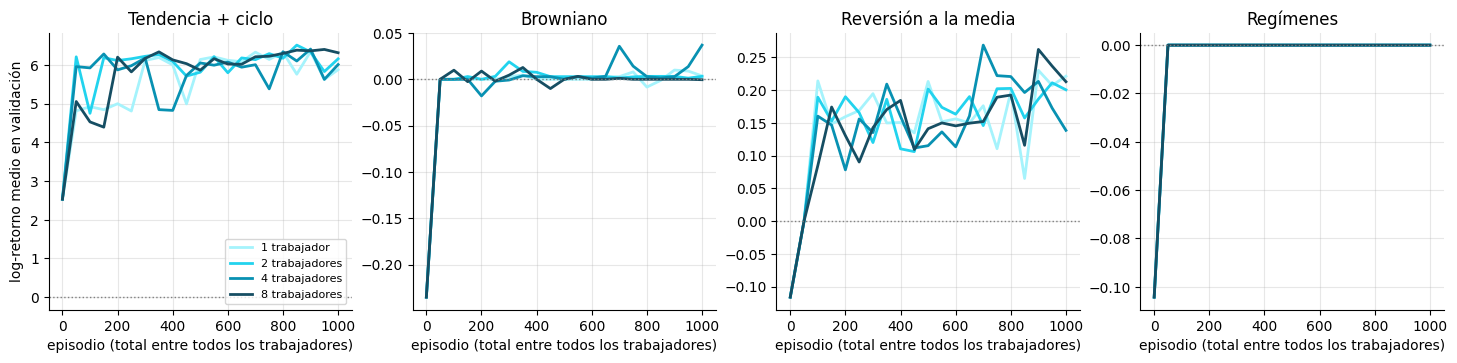

In [20]:
f_w = CACHE / "runs_trabajadores.joblib"
if RECOMPUTE or not f_w.exists():
    RUNS_W = entrenar_varios([tarea(g, MEJORES_PARAMS[g], N_EP_EXTRA, s, EVAL_CADA, workers=w) for w in WORKERS_ABL for g in GENS for s in SEMILLAS_EXTRA],
                             "trabajadores")
    for r, cv in zip(RUNS_W, curvas_validacion(RUNS_W)):
        r["val"] = [cv[j] for j in range(len(r["snap_ep"]))]
    dump(RUNS_W, f_w)
else:
    RUNS_W = load(f_w)
EVAL_W = evaluar_finales(RUNS_W)

filas = []
for w in WORKERS_ABL:
    for g in GENS:
        idx = [i for i, r in enumerate(RUNS_W) if r["workers"] == w and r["gen"] == g]
        d = [EVAL_W[i] for i in idx]
        conv = float(np.median([convergence_episode(list(RUNS_W[i]["snap_ep"]), RUNS_W[i]["val"]) for i in idx]))
        filas.append({"trabajadores": w, "mercado": g, "log-ret. test": np.mean([x["log_ret"].mean() for x in d]),
                      "± entre semillas": np.std([x["log_ret"].mean() for x in d]), "episodios hasta converger": conv,
                      "ms/episodio (reloj)": COSTE[(w, g)], "s hasta converger (reloj)": conv * COSTE[(w, g)] / 1000})
trab = pd.DataFrame(filas)
display(trab.pivot(index="mercado", columns="trabajadores", values="log-ret. test").loc[GENS].round(3).rename_axis("log-retorno en test"))
display(trab.pivot(index="mercado", columns="trabajadores", values="episodios hasta converger").loc[GENS].rename_axis("episodios hasta converger"))
display(trab.pivot(index="mercado", columns="trabajadores", values="s hasta converger (reloj)").loc[GENS].round(1).rename_axis("segundos de reloj hasta converger"))

fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
cmap_w = {1: "#a5f3fc", 2: "#22d3ee", 4: "#0891b2", 8: "#164e63"}
for ax, g in zip(axs, GENS):
    for w in WORKERS_ABL:
        rs = [r for r in RUNS_W if r["workers"] == w and r["gen"] == g]
        val = np.array([r["val"] for r in rs])
        ax.plot(rs[0]["snap_ep"], val.mean(0), color=cmap_w[w], lw=2, label=f"{w} trabajador{'es' if w > 1 else ''}")
    ax.axhline(0, color="gray", ls=":", lw=1)
    ax.set_title(g)
    ax.set_xlabel("episodio (total entre todos los trabajadores)")
axs[0].set_ylabel("log-retorno medio en validación")
axs[0].legend(fontsize=8, loc="lower right")
plt.savefig(FIGS / "trabajadores.png", bbox_inches="tight")
plt.show()

**Lectura de la comparación de trabajadores.**

- **Tiempo.** El tiempo de reloj por episodio baja de 48 ms (1 trabajador) a 29 (2) y 25 (4), y se queda en 27 con 8: **la aceleración es casi lineal hasta 2, se frena en 4 y no mejora con 8**, aunque la máquina tiene 12 núcleos. El coste de CPU (trabajadores × reloj) crece sin parar (48 → 217 ms): más trabajadores no ahorran trabajo, solo lo reparten. Una causa plausible de la saturación es la contención en la memoria compartida y en el contador de episodios, además de copiar los pesos globales al inicio de cada episodio (no se ha medido por separado). La hipótesis 4 se cumple a medias.
- **Rendimiento.** El log-retorno en test no depende de forma clara del número de trabajadores: en *tendencia + ciclo* varía entre 6,08 y 6,48 sin orden, y en *reversión* entre 0,12 y 0,17, dentro del ruido entre semillas. El desfase entre gradientes y pesos, que es el precio de lo asíncrono, **no se nota** en una red tan pequeña. Con un solo trabajador (actor-crítico de *n* pasos síncrono) el resultado es igual de bueno.
- **Episodios hasta converger.** Sin tendencia clara (en *reversión*, entre 450 y 725), con solo 2 semillas por celda; no hay que leer más en esos números.
- **Conclusión.** Lo asíncrono da velocidad (hasta ~2× de reloj), no mejor aprendizaje.

### 8.3 Entropía: el sustituto de $\epsilon$

En A3C no hay $\epsilon$-greedy: la exploración viene de que la política es estocástica, y el coeficiente de entropía $\beta$ evita que se vuelva determinista demasiado pronto. Se entrena con $\beta \in \{0;\ 0{,}001;\ 0{,}01;\ 0{,}05\}$ **constante** (el resto, los hiperparámetros elegidos) y se mira el rendimiento en test y la entropía media de la política resultante.

In [21]:
BETAS = (0.0, 0.001, 0.01, 0.05)
f_b = CACHE / "runs_entropia.joblib"
if RECOMPUTE or not f_b.exists():
    RUNS_B = entrenar_varios([tarea(g, {**MEJORES_PARAMS[g], "beta": be, "beta_final": 1.0}, N_EP_EXTRA, s, EVAL_CADA)
                              for be in BETAS for g in GENS for s in SEMILLAS_EXTRA], "entropía")
    for r in RUNS_B:
        r["beta"] = r["hp"]["beta"]
    dump(RUNS_B, f_b)
else:
    RUNS_B = load(f_b)
EVAL_B = evaluar_finales(RUNS_B)


def entropia_media(run, g):
    """Entropía media (en nats) de π en los estados de las series de validación, estando en cada posición."""
    pol = A.politica_de(run, len(run["snap_ep"]) - 1)
    hs = []
    for s in VAL[g][:10]:
        env = SimpleTradingEnv(s)
        obs, _ = env.reset()
        done = False
        while not done:
            l = pol.logits(obs)
            a2 = A.ACCIONES_VALIDAS[int(obs[1] > 0.5)]
            p2 = 1.0 / (1.0 + np.exp(np.clip(l[a2[0]] - l[a2[1]], -30, 30)))
            hs.append(-sum(q * np.log(max(q, 1e-12)) for q in (p2, 1 - p2)))
            obs, _, done, _, _ = env.step(1)
    return float(np.mean(hs))


filas = []
for be in BETAS:
    for g in GENS:
        idx = [i for i, r in enumerate(RUNS_B) if r["beta"] == be and r["gen"] == g]
        d = [EVAL_B[i] for i in idx]
        filas.append({"beta": be, "mercado": g, "log-ret. test": np.mean([x["log_ret"].mean() for x in d]),
                      "operaciones": np.mean([x["trades"].mean() for x in d]),
                      "entropía de π (nats; máx. 0,69)": np.mean([entropia_media(RUNS_B[i], g) for i in idx])})
ent = pd.DataFrame(filas)
display(ent.pivot(index="mercado", columns="beta", values="log-ret. test").loc[GENS].round(3).rename_axis("log-retorno en test"))
display(ent.pivot(index="mercado", columns="beta", values="entropía de π (nats; máx. 0,69)").loc[GENS].round(2).rename_axis("entropía media de la política final"))

entropía: 32 entrenamientos en 996 s


beta,0.000,0.001,0.010,0.050
log-retorno en test,,,,
Tendencia + ciclo,6.288,6.228,6.187,6.437
Browniano,-0.031,-0.038,-0.055,-0.116
Reversión a la media,0.176,0.117,0.165,0.131
Regímenes,0.000,0.000,0.000,0.000


beta,0.000,0.001,0.010,0.050
entropía media de la política final,,,,
Tendencia + ciclo,0.10,0.07,0.08,0.39
Browniano,0.55,0.54,0.50,0.65
Reversión a la media,0.13,0.03,0.25,0.56
Regímenes,0.01,0.01,0.14,0.50


**Lectura de la entropía.**

- El rendimiento en test **no cambia de forma apreciable** con β en los mercados con señal (tendencia: 6,19–6,44; reversión: 0,12–0,18; diferencias del tamaño del ruido entre semillas). La hipótesis 5 (colapso sin entropía) **no se confirma**: con β = 0 la política es muy determinista (entropía media 0,01–0,13 en tres mercados, frente a un máximo de ln 3 = 1,10) pero aprende igual de bien.
- Donde sí se ve efecto es **al sobrar entropía en el mercado sin señal**: en *browniano*, β = 0,05 mantiene la política cerca de aleatoria (entropía 0,65) y empeora el resultado a −0,116 (frente a −0,031 con β = 0), porque operar al azar solo paga comisiones.
- Con β grande la entropía final sube (en regímenes, de 0,01 a 0,50), pero la política *greedy* sigue sin operar.

### 8.4 Política greedy frente a estocástica

A3C entrena una política **estocástica** $\pi$, pero en test se evalúa la *greedy* (la acción de mayor probabilidad), igual que en el resto de algoritmos. ¿Qué pasa si se evalúa con la política con la que se ha entrenado, muestreando de $\pi$? Es la misma pregunta que se hizo con SARSA (*on-policy*): si explorar cuesta (aquí, cada operación aleatoria paga comisión), la política estocástica debería rendir peor.

In [22]:
EVAL_EST = evaluar_finales(RUNS, estocastica=True)
filas = []
for g in GENS:
    idx = [i for i, r in enumerate(RUNS) if r["gen"] == g]
    for nombre, ev in (("greedy", EVAL_RUNS), ("estocástica", EVAL_EST)):
        d = [ev[i] for i in idx]
        filas.append({"mercado": g, "política": nombre, "log-ret. test": np.mean([x["log_ret"].mean() for x in d]),
                      "± entre semillas": np.std([x["log_ret"].mean() for x in d]), "operaciones": np.mean([x["trades"].mean() for x in d])})
est = pd.DataFrame(filas)
display(est.pivot(index="mercado", columns="política", values="log-ret. test").loc[GENS].round(3).rename_axis("log-retorno en test"))
display(est.pivot(index="mercado", columns="política", values="operaciones").loc[GENS].round(1).rename_axis("operaciones por episodio"))

política,estocástica,greedy
log-retorno en test,,
Tendencia + ciclo,6.423,6.412
Browniano,-0.089,-0.073
Reversión a la media,0.122,0.114
Regímenes,-0.013,0.000


política,estocástica,greedy
operaciones por episodio,,
Tendencia + ciclo,30.6,29.8
Browniano,22.8,13.7
Reversión a la media,44.8,37.2
Regímenes,4.9,0.0


**Lectura de greedy frente a estocástica.** En los mercados con señal la diferencia es mínima (tendencia: 6,423 estocástica frente a 6,412 *greedy*; reversión: 0,122 frente a 0,114, dentro del ruido). A diferencia de SARSA, **explorar apenas cuesta**: la entropía decae durante el entrenamiento y la política final es casi determinista. Solo se nota en los mercados sin señal: en *regímenes* la estocástica opera 4,9 veces por serie y pierde (−0,013), mientras la *greedy* se queda fuera (0,000); y en *browniano* opera 23 veces frente a 14 y pierde un poco más (−0,089 frente a −0,073). Por eso se evalúa la *greedy*.

### 8.5 Estado ampliado: lo que una red puede usar sin discretizar

En la práctica 1 la mejora más grande vino de ampliar el estado con la **volatilidad reciente** y la **distancia a la media de 20 pasos** (`ExtendedTradingEnv`): Q-Learning pasó de +17 % a +37 % en reversión a la media y de +4 % a +17 % en regímenes. Con una tabla eso exigía discretizar cuatro variables; una red las recibe tal cual. Se entrena A3C con los mismos hiperparámetros y la misma red, solo con cuatro entradas en vez de dos.

In [23]:
f_ext = CACHE / "runs_estado_ampliado.joblib"
if RECOMPUTE or not f_ext.exists():
    RUNS_EXT = entrenar_varios([tarea(g, MEJORES_PARAMS[g], N_EP_FINAL, s, EVAL_CADA, env_name="ExtendedTradingEnv") for g in GENS for s in SEMILLAS_FINAL],
                               "estado ampliado")
    for r, cv in zip(RUNS_EXT, curvas_validacion(RUNS_EXT)):
        r["val"] = [cv[j] for j in range(len(r["snap_ep"]))]
    dump(RUNS_EXT, f_ext)
else:
    RUNS_EXT = load(f_ext)
EVAL_EXT = evaluar_finales(RUNS_EXT)
ext = pd.DataFrame([fila([EVAL_EXT[i] for i, r in enumerate(RUNS_EXT) if r["gen"] == g], "A3C (estado ampliado)", g,
                         [r for r in RUNS_EXT if r["gen"] == g]) for g in GENS]).set_index(["Generador", "Agente"])
comp = pd.DataFrame({
    "Q-Learning (tabular)": [prac1.loc[(g, "Q-Learning"), "Log-ret. medio"] for g in GENS],
    "Q-Learning estado ampliado (tabular)": [prac1.loc[(g, "Q-Learning (estado ampliado)"), "Log-ret. medio"] for g in GENS],
    "A3C": [principal.loc[(g, "A3C"), "Log-ret. medio"] for g in GENS],
    "A3C estado ampliado": [ext.loc[(g, "A3C (estado ampliado)"), "Log-ret. medio"] for g in GENS],
    "Buy & Hold": [principal.loc[(g, "Buy & Hold"), "Log-ret. medio"] for g in GENS]}, index=GENS)
print("Log-retorno medio en test:")
display(comp.round(3))
display(ext[["Log-ret. medio", "Ret. geométrico (%)", "% series > B&H", "Sharpe", "Operaciones", "Std log-ret. entre semillas", "Episodios hasta convergencia"]].style.format(FMT, na_rep="—"))

estado ampliado: 20 entrenamientos en 1002 s


Log-retorno medio en test:


,Q-Learning (tabular),Q-Learning estado ampliado (tabular),A3C,A3C estado ampliado,Buy & Hold
Tendencia + ciclo,6.338,6.579,6.412,6.694,3.316
Browniano,0.000,-0.006,-0.073,-0.070,-0.062
Reversión a la media,0.155,0.317,0.114,0.316,-0.005
Regímenes,0.040,0.154,0.000,0.000,-0.128


,,Log-ret. medio,Ret. geométrico (%),% series > B&H,Sharpe,Operaciones,Std log-ret. entre semillas,Episodios hasta convergencia
Generador,Agente,,,,,,,
Tendencia + ciclo,A3C (estado ampliado),6.694,"80,680.0",99,3.21,32.7,0.028,150
Browniano,A3C (estado ampliado),-0.070,-6.7,49,0.00,23.6,0.036,950
Reversión a la media,A3C (estado ampliado),0.316,37.1,94,0.78,33.9,0.023,1000
Regímenes,A3C (estado ampliado),0.000,0.0,58,0.00,0.0,0.000,150


**Lectura del estado ampliado.**

- **Tendencia + ciclo:** 6,694 (±0,03) frente a 6,412, con mucha menos varianza entre semillas (de ±0,19 a ±0,03), y mejor que Q-Learning tabular con el estado ampliado (6,579). Es el mejor resultado de todo el trabajo en este mercado.
- **Reversión a la media:** de 0,114 a **0,316** (×2,8), 94 % de series por encima de B&H, Sharpe 0,78 y *drawdown* del 19 %. Empata con Q-Learning tabular ampliado (0,317): ampliar el estado sirve más que cambiar de algoritmo, pero aquí la red lo aprovecha sin discretizar nada.
- **Browniano:** sin cambios (−0,070): no hay señal que la volatilidad o la distancia a la media puedan revelar.
- **Regímenes:** **A3C sigue sin operar** (0,000), mientras que Q-Learning ampliado llega a +0,154. Los hiperparámetros se eligieron con el estado de dos variables y no se reajustaron para el ampliado, así que no prueba que A3C no pueda; sí muestra que la señal débil de este mercado necesitaría una búsqueda aparte.

## 9. Conclusiones y limitaciones

**Hipótesis de la sección 4 frente a los resultados**

| # | Hipótesis | Resultado |
|---|---|---|
| 1 | Tendencia + ciclo: *momentum* con histéresis, en pocos episodios | **Confirmada en lo cualitativo**: 6,41 frente a 3,32 de B&H y 6,10 de la regla, con 30 operaciones frente a 93. **No en lo de pocos episodios**: 350 (DQN: 60). |
| 2 | Reversión: γ > 0 imprescindible y curva más inestable | **Parcialmente refutada**: la mejor configuración usa γ = 0 (aunque en media γ = 0,5 es mejor). La inestabilidad sí se cumple. |
| 3 | Browniano y regímenes: acabar fuera con la política *greedy* | **Regímenes: sí** (0,000). **Browniano: no** (−0,073, 14 operaciones): la búsqueda eligió por ruido. |
| 4 | Trabajadores: menos tiempo de reloj, desfase irrelevante | **Parcialmente**: la aceleración se satura en 4 (de 48 a 25 ms/episodio) y el rendimiento no depende del nº de trabajadores. |
| 5 | Sin entropía, colapso; con mucha, demasiado aleatoria | **No confirmada**: β = 0 aprende igual; solo β alto perjudica en *browniano*. |
| 6 | Coste por episodio mayor que en tabla, reducido por el paralelismo | **Confirmada**: 25–67 ms de reloj, pero 99–269 ms de CPU, similar a DQN (134–204 ms). |

**Conclusiones**

1. **A3C aprende la misma estrategia que el resto** donde hay señal (momentum con histéresis, contrarian con histéresis), pero **no es mejor que los tabulares ni que DQN**: en *tendencia + ciclo* queda por encima de DQN y por debajo de Monte Carlo; en *reversión* queda por debajo de todos (0,114 frente a 0,155–0,238); en *browniano* y *regímenes* no mejora quedarse fuera.
2. **Lo que más mejora el resultado sigue siendo el estado, no el algoritmo**: con volatilidad y distancia a la media, A3C pasa de 0,114 a 0,316 en reversión y de 6,41 a 6,69 en tendencia + ciclo, mucho más que cualquier ajuste de hiperparámetros, número de trabajadores o entropía.
3. **El paralelismo asíncrono acelera el reloj (hasta ~2×) pero no el aprendizaje**, y encarece la CPU.
4. **Donde no hay señal, hay que cuidar la selección.** Una búsqueda que puntúa con la validación elige ruido (browniano) y puede dejar al agente operando en pérdidas; un criterio que prefiera «no operar» salvo mejora clara habría evitado el −0,073.

**Limitaciones**

- **A3C asíncrono no es reproducible bit a bit**: el orden en que los trabajadores actualizan los pesos depende del planificador del sistema, así que dos ejecuciones con la misma semilla dan resultados parecidos pero no idénticos. Por eso hay 5 semillas y se reporta su desviación. Las cifras de esta libreta se guardan en `cache_a3c/` y `resultados_a3c.csv`; con `RECOMPUTE = True` se recalcularía todo (varias horas).
- **Búsqueda limitada**: 16 configuraciones por mercado, 500 episodios y 2 semillas; en mercados de señal débil la elección es ruidosa.
- **Tiempos**: los de la búsqueda no son comparables (entrenamientos simultáneos); los de coste por episodio se midieron aparte.
- **Comparación de episodios**: tabulares 3000, DQN 200 y A3C 1500 episodios; los «episodios hasta converger» dependen además del criterio de banda.

## Guardar resultados

In [24]:
tabla_total = pd.concat([tabla, ext]).astype(float)
destino = CACHE if MODO_RAPIDO else Path(".")          # el modo rápido no pisa los resultados buenos
tabla_total.round(4).to_csv(destino / "resultados_a3c.csv", encoding="utf-8-sig")
pd.DataFrame(MEJORES_PARAMS).T.to_csv(destino / "hiperparametros_a3c.csv", encoding="utf-8-sig")
print("Guardado: resultados_a3c.csv, hiperparametros_a3c.csv en", destino, "y figuras en", FIGS)

Guardado: resultados_a3c.csv, hiperparametros_a3c.csv en . y figuras en figuras_a3c
